
# Numpy Implementation of CNN


## Q1(i): Convolution Function

Accepts as input an image, a filter kernel, stride, padding, and the non-linear function.  
Supports multi-channel input and corresponding kernel volumes.  
Verified with: **sigmoid, tanh, ReLU, PReLU**.

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
np.random.seed(42)

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

In [23]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

def tanh_act(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def prelu(x, alpha=0.25):
    return np.where(x > 0, x, alpha * x)

ACTIVATIONS = {
    'sigmoid': sigmoid,
    'tanh': tanh_act,
    'relu': relu,
    'prelu': prelu
}

sigmoid  -> shape: (28, 28), range: [0.4131, 0.7376]
tanh     -> shape: (28, 28), range: [-0.3374, 0.7754]
relu     -> shape: (28, 28), range: [0.0000, 1.0336]
prelu    -> shape: (28, 28), range: [-0.0878, 1.0336]


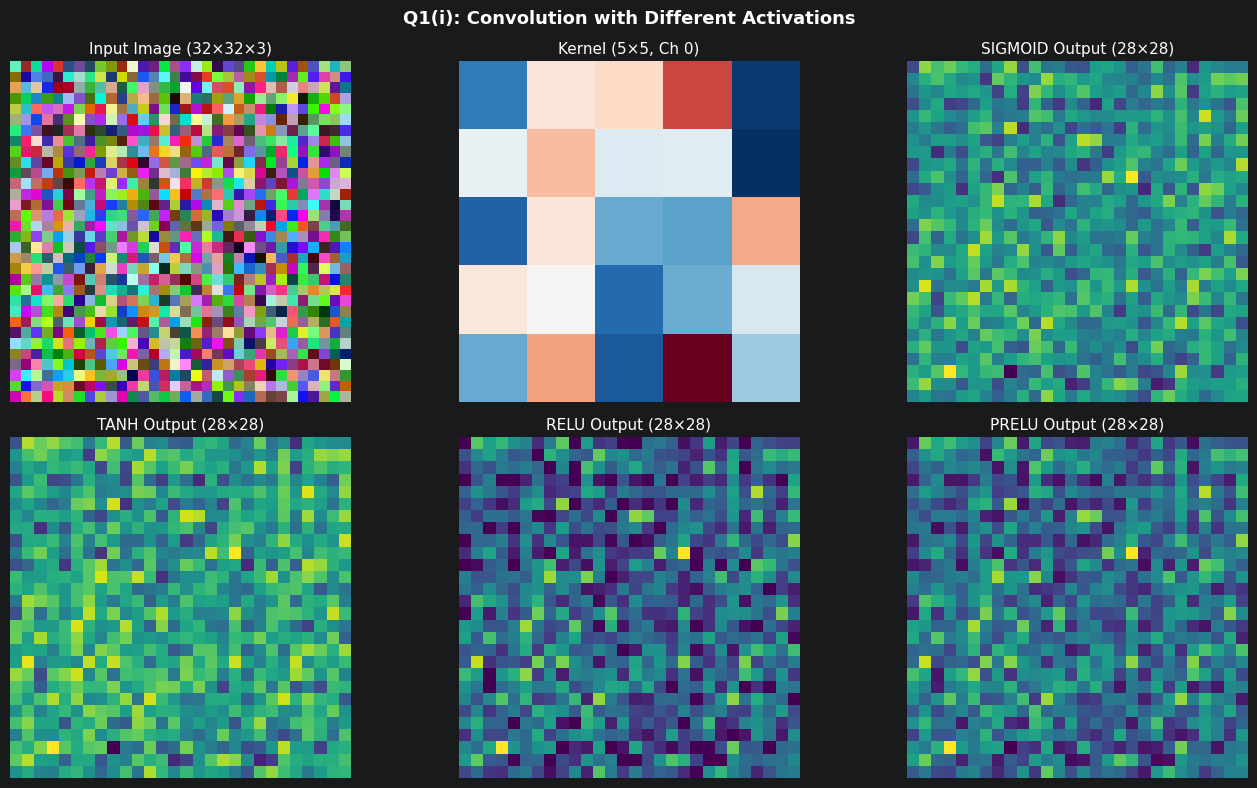

In [24]:
def pad_input(image, padding):
    if padding == 0:
        return image
    pad_width = ((padding, padding), (padding, padding), (0, 0))
    return np.pad(image, pad_width, mode='constant')

def convolution_function(image, kernel, stride=1, padding=0, activation='relu'):
    if image.ndim == 2:
        image = image[:, :, np.newaxis]
    if kernel.ndim == 2:
        kernel = kernel[:, :, np.newaxis]
    H, W, C = image.shape
    kH, kW, kC = kernel.shape
    assert C == kC, f"Channel mismatch: image has {C}, kernel has {kC}"
    padded = pad_input(image, padding)

    pH, pW, _ = padded.shape
    oH = (pH - kH) // stride + 1
    oW = (pW - kW) // stride + 1
    output = np.zeros((oH, oW))

    for i in range(oH):
        for j in range(oW):
            region = padded[i*stride:i*stride+kH, j*stride:j*stride+kW]
            output[i, j] = np.sum(region * kernel)
    return ACTIVATIONS[activation](output)

np.random.seed(42)
sample_image = np.random.rand(32, 32, 3).astype(np.float32)
sample_kernel = np.random.randn(5, 5, 3).astype(np.float32) * 0.1

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
axes[0].imshow(sample_image)
axes[0].set_title('Input Image (32×32×3)', fontsize=11)
axes[1].imshow(sample_kernel[:, :, 0], cmap='RdBu_r')
axes[1].set_title('Kernel (5×5, Ch 0)', fontsize=11)
activations = ['sigmoid', 'tanh', 'relu', 'prelu']

for i, act in enumerate(activations, start=2):
    out = convolution_function(sample_image, sample_kernel, activation=act)
    axes[i].imshow(out)
    axes[i].set_title(f'{act.upper()} Output ({out.shape[0]}×{out.shape[1]})', fontsize=11)
    print(f"{act:8s} -> shape: {out.shape}, range: [{out.min():.4f}, {out.max():.4f}]")

for ax in axes:
    ax.axis('off')

plt.suptitle('Q1(i): Convolution with Different Activations', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Q1(ii): Pooling Function

Accepts the activation map, a pooling function (max/average), and stride.  
Outputs the appropriately pooled activation map.

Input activation map shape: (32, 32)
  max      pooling -> output shape: (16, 16)
  average  pooling -> output shape: (16, 16)


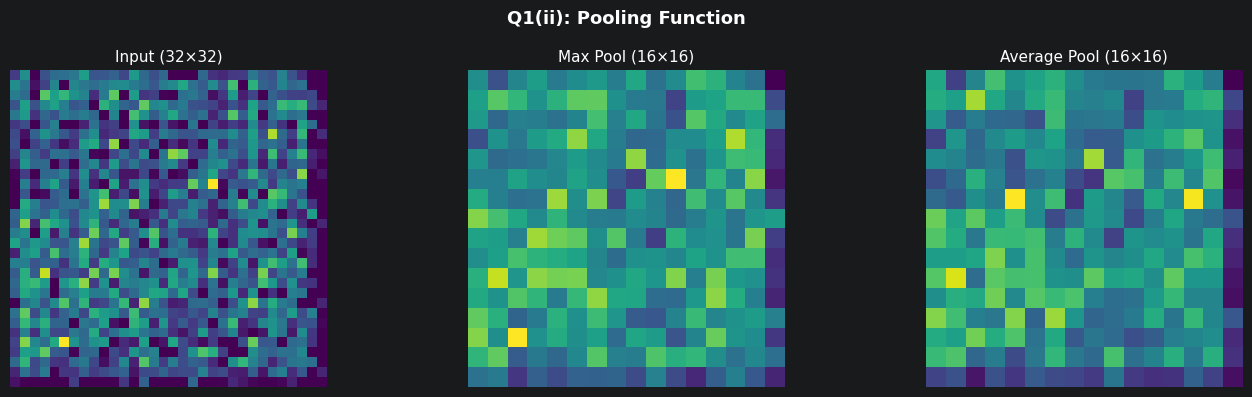

In [25]:
def pooling_function(activation_map, pool_size=2, stride=2, mode='max'):
    H, W = activation_map.shape
    oH = (H - pool_size) // stride + 1
    oW = (W - pool_size) // stride + 1
    pooled = np.zeros((oH, oW))
    for i in range(oH):
        for j in range(oW):
            region = activation_map[i*stride:i*stride+pool_size, j*stride:j*stride+pool_size]
            if mode == 'max':
                pooled[i, j] = np.max(region)
            elif mode == 'average':
                pooled[i, j] = np.mean(region)
            else:
                raise ValueError(f"Unknown pooling mode: {mode}")
    return pooled

act_map = convolution_function(sample_image, sample_kernel, stride=1, padding=2, activation='relu')
print(f"Input activation map shape: {act_map.shape}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(act_map)
axes[0].set_title(f'Input ({act_map.shape[0]}×{act_map.shape[1]})', fontsize=11)
axes[0].axis('off')

for idx, mode in enumerate(['max', 'average']):
    pooled = pooling_function(act_map, pool_size=2, stride=2, mode=mode)
    axes[idx + 1].imshow(pooled, cmap='viridis')
    axes[idx + 1].set_title(f'{mode.capitalize()} Pool ({pooled.shape[0]}×{pooled.shape[1]})', fontsize=11)
    axes[idx + 1].axis('off')
    print(f"  {mode:8s} pooling -> output shape: {pooled.shape}")

plt.suptitle('Q1(ii): Pooling Function', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Q1(iii): Convolution Layer Function

Accepts an input volume, **multiple** filter kernels, stride, padding, and activation.  
Generates an output **activation volume** (W×H×C_out).  
Verifies output has expected size.

Input volume shape:  (32, 32, 3)
Kernels shape:       (4, 5, 5, 3)
Output volume shape: (32, 32, 4)
Expected output size: (32, 32, 4)


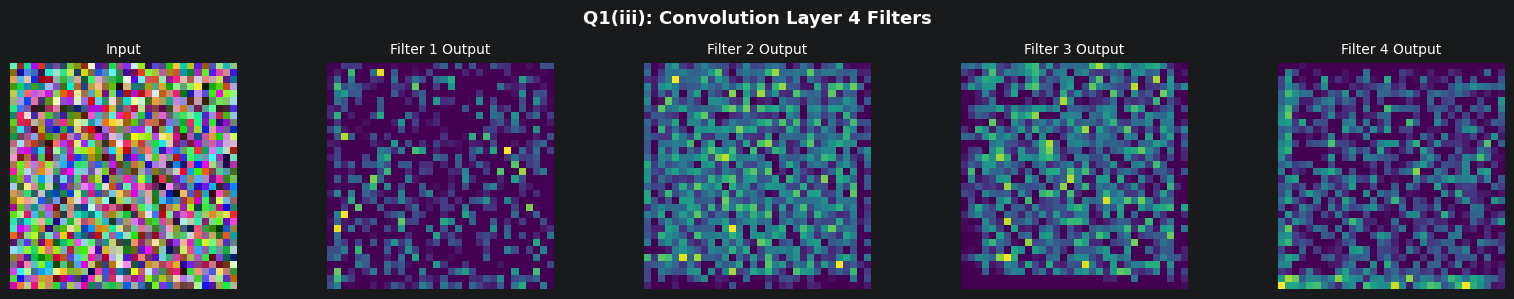

In [26]:
def convolution_layer(input_volume, kernels, stride=1, padding=0, activation='relu'):
    if isinstance(kernels, np.ndarray) and kernels.ndim == 4:
        kernel_list = [kernels[i] for i in range(kernels.shape[0])]
    else:
        kernel_list = kernels
    outputs = []

    for k in kernel_list:
        act_map = convolution_function(input_volume, k, stride=stride, padding=padding, activation=activation)
        outputs.append(act_map)
    output_volume = np.stack(outputs, axis=-1)
    return output_volume

np.random.seed(42) 
sample_image = np.random.rand(32, 32, 3).astype(np.float32)
sample_kernel = np.random.randn(5, 5, 3).astype(np.float32) * 0.1
num_kernels = 4
kernels_set = np.random.randn(num_kernels, 5, 5, 3).astype(np.float32) * 0.1
output_vol = convolution_layer(sample_image, kernels_set, stride=1, padding=2, activation='relu')

print(f"Input volume shape:  {sample_image.shape}")
print(f"Kernels shape:       ({num_kernels}, 5, 5, 3)")
print(f"Output volume shape: {output_vol.shape}")

expected_h = (32 + 2*2 - 5) // 1 + 1
expected_w = (32 + 2*2 - 5) // 1 + 1

print(f"Expected output size: ({expected_h}, {expected_w}, {num_kernels})")
assert output_vol.shape == (expected_h, expected_w, num_kernels)

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
axes[0].imshow(sample_image)
axes[0].set_title('Input', fontsize=10)
axes[0].axis('off')

for i in range(4):
    axes[i+1].imshow(output_vol[:, :, i], cmap='viridis')
    axes[i+1].set_title(f'Filter {i+1} Output', fontsize=10)
    axes[i+1].axis('off')

plt.suptitle('Q1(iii): Convolution Layer 4 Filters', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Q1(iv): Pooling Layer Function

Accepts input activation map volume, pooling function, and stride.  
Generates pooled output volume.

Input volume shape:  (32, 32, 4)
Output volume shape: (16, 16, 4)


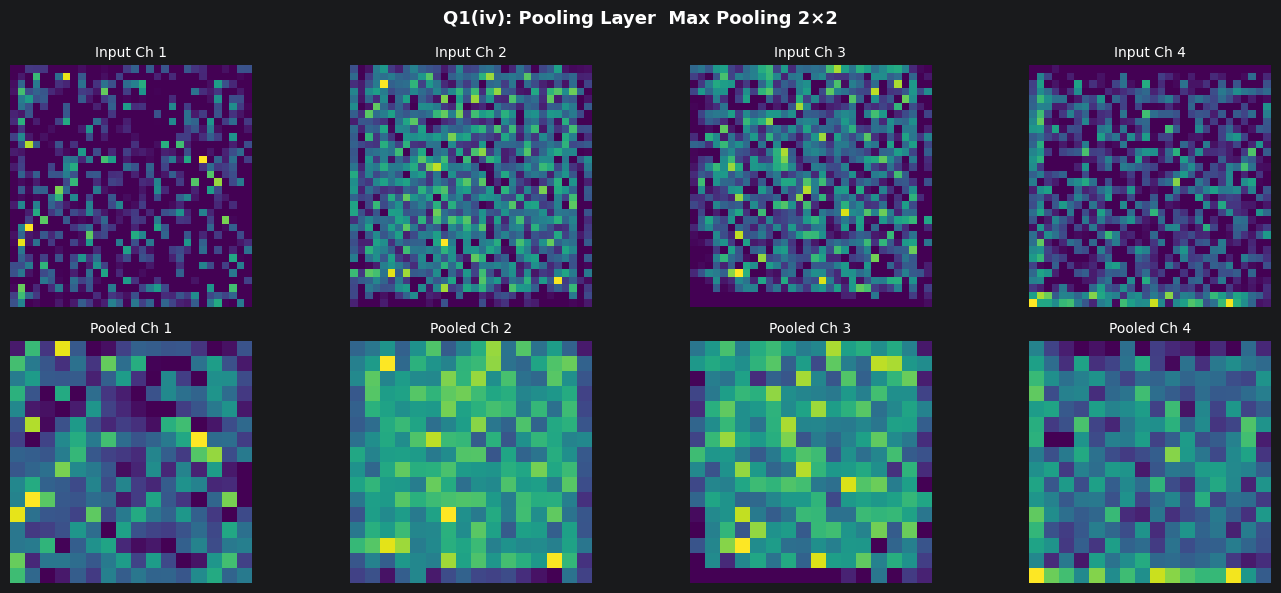

In [27]:
def pooling_layer(input_volume, pool_size=2, stride=2, mode='max'):
    H, W, C = input_volume.shape
    
    outputs = []
    for c in range(C):
        pooled = pooling_function(input_volume[:, :, c], pool_size=pool_size, stride=stride, mode=mode)
        outputs.append(pooled)
    
    output_volume = np.stack(outputs, axis=-1)
    return output_volume


np.random.seed(42)

pooled_vol = pooling_layer(output_vol, pool_size=2, stride=2, mode='max')
print(f"Input volume shape:  {output_vol.shape}")
print(f"Output volume shape: {pooled_vol.shape}")

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i in range(4):
    axes[0, i].imshow(output_vol[:, :, i])
    axes[0, i].set_title(f'Input Ch {i+1}', fontsize=10)
    axes[0, i].axis('off')
    axes[1, i].imshow(pooled_vol[:, :, i])
    axes[1, i].set_title(f'Pooled Ch {i+1}', fontsize=10)
    axes[1, i].axis('off')
plt.suptitle('Q1(iv): Pooling Layer  Max Pooling 2×2', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Q1(v): Flattening Function

Accepts the activation map volume and generates a vector of specified size.  
Has a weight matrix whose size matches input and desired output sizes.  

In [28]:
def flatten_function(input_volume, output_size=None, weights=None):
    flat = input_volume.flatten()
    input_size = flat.shape[0]
    
    if output_size is None:
        output_size = input_size
    
    if weights is None:
        if input_size == output_size:
            return flat
        else:
            weights = np.random.randn(input_size, output_size).astype(np.float32) * 0.01
    
    assert weights.shape == (input_size, output_size), \
        f"Weight shape mismatch: expected ({input_size}, {output_size}), got {weights.shape}"
    
    output_vector = flat @ weights
    return output_vector


np.random.seed(42)
flat_vec = flatten_function(pooled_vol)
print(f"Input volume shape: {pooled_vol.shape}")
print(f"Flattened vector length: {flat_vec.shape[0]}")
print(f"Expected: {pooled_vol.size} (= {pooled_vol.shape[0]} × {pooled_vol.shape[1]} × {pooled_vol.shape[2]})")
for i in range(1024):
    print(f"  flat_vec[{i}] = {flat_vec[i]:.4f}")

Input volume shape: (16, 16, 4)
Flattened vector length: 1024
Expected: 1024 (= 16 × 16 × 4)
  flat_vec[0] = 0.0684
  flat_vec[1] = 0.3683
  flat_vec[2] = 0.3499
  flat_vec[3] = 0.4481
  flat_vec[4] = 0.6453
  flat_vec[5] = 0.4405
  flat_vec[6] = 0.4783
  flat_vec[7] = 0.2028
  flat_vec[8] = 0.1493
  flat_vec[9] = 0.5647
  flat_vec[10] = 0.6342
  flat_vec[11] = 0.0844
  flat_vec[12] = 0.9203
  flat_vec[13] = 0.3506
  flat_vec[14] = 0.3871
  flat_vec[15] = 0.0000
  flat_vec[16] = 0.2651
  flat_vec[17] = 0.5589
  flat_vec[18] = 0.5535
  flat_vec[19] = 0.0483
  flat_vec[20] = 0.0000
  flat_vec[21] = 0.7804
  flat_vec[22] = 0.6110
  flat_vec[23] = 0.0000
  flat_vec[24] = 0.0377
  flat_vec[25] = 0.3311
  flat_vec[26] = 0.4874
  flat_vec[27] = 0.3654
  flat_vec[28] = 0.1831
  flat_vec[29] = 0.4863
  flat_vec[30] = 0.3768
  flat_vec[31] = 0.0000
  flat_vec[32] = 0.2949
  flat_vec[33] = 0.6793
  flat_vec[34] = 0.4141
  flat_vec[35] = 0.1853
  flat_vec[36] = 0.2805
  flat_vec[37] = 0.9021
  fla

## Q1(vi): Multilayer Perceptron

Accepts a vector, hidden layer configuration, activation, and output size.  
Generates output with and without softmax.

In [29]:
def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum()


def mlp(input_vector, hidden_sizes, output_size, activation='relu', weights=None, biases=None):
    act_fn = ACTIVATIONS[activation]
    layer_sizes = [input_vector.shape[0]] + hidden_sizes + [output_size]
    num_layers = len(layer_sizes) - 1
    

    if weights is None:
        weights = []
        for i in range(num_layers):
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]).astype(np.float32) * np.sqrt(2.0 / layer_sizes[i])
            weights.append(w)
    if biases is None:
        biases = [np.zeros(layer_sizes[i+1]).astype(np.float32) for i in range(num_layers)]
    

    x = input_vector
    for i in range(num_layers - 1):
        x = x @ weights[i] + biases[i]
        x = act_fn(x)
    
    output_no_softmax = x @ weights[-1] + biases[-1]
    output_with_softmax = softmax(output_no_softmax)
    
    return output_no_softmax, output_with_softmax


np.random.seed(42)

test_input = np.random.randn(256).astype(np.float32)
logits, probs = mlp(test_input, hidden_sizes=[128, 64], output_size=10, activation='relu')

print(f"Input vector size: {test_input.shape[0]}")
print(f"Hidden layers: [128, 64]")
print(f"Output (no softmax):   shape={logits.shape}, range=[{logits.min():.4f}, {logits.max():.4f}]")
print(f"Output (with softmax): shape={probs.shape}, sum={probs.sum():.6f}")
print(f"Predicted class: {np.argmax(probs)}")
print("")
print("First 10 probabilities:")
for i in range(10):
    print(f"  probs[{i}] = {probs[i]:.4f}")


Input vector size: 256
Hidden layers: [128, 64]
Output (no softmax):   shape=(10,), range=[-2.6140, 2.8736]
Output (with softmax): shape=(10,), sum=1.000000
Predicted class: 9

First 10 probabilities:
  probs[0] = 0.0259
  probs[1] = 0.0207
  probs[2] = 0.0886
  probs[3] = 0.0035
  probs[4] = 0.2290
  probs[5] = 0.0457
  probs[6] = 0.0387
  probs[7] = 0.0940
  probs[8] = 0.0019
  probs[9] = 0.4521


## Q1(vii): Feed-Forward CNN Architecture

- Input image of size 32 × 32 × 3 (CIFAR-10 dataset)
- Convolution layer with 4 kernels of size 5 × 5, ReLU activation, stride 1, and same spatial dimen-
sions as input
- Max pooling layer of size 2 × 2 with stride 2
- Convolution layer with 4 kernels of size 5 × 5 × 4, ReLU activation, stride 1, and same spatial
dimensions
- Max pooling layer of size 2 × 2 with stride 2
- Flattening layer (identity mapping)
- MLP with one hidden layer of 49 nodes and an output layer of 10 nodes
- ReLU activation and softmax output

Verify that the network accepts a 32×32×3 image and outputs a 10-dim vector.

Input:      (32, 32, 3)
Conv1:      (32, 32, 4)  (4 kernels 5×5, ReLU, same padding)
MaxPool1:   (16, 16, 4)  (2×2, stride 2)
Conv2:      (16, 16, 4)  (4 kernels 5×5×4, ReLU, same padding)
MaxPool2:   (8, 8, 4)  (2×2, stride 2)
Flatten:    (256,)   (identity mapping)
MLP Out:    (10,)   (hidden=49, output=10, ReLU + softmax)

--- Verification ---
Input shape:  (32, 32, 3) 
Output shape: (10,) 
Output sums to 1: 1.000000 
Predicted class: 0 (probability: 0.2232)

Intermediate shapes:
  conv1: (32, 32, 4)
  pool1: (16, 16, 4)
  conv2: (16, 16, 4)
  pool2: (8, 8, 4)
  flatten: (256,)
  logits: (10,)
  probs: (10,)

First 10 probabilities and logits:
  probs[0] = 0.2232
  probs[1] = 0.1070
  probs[2] = 0.0936
  probs[3] = 0.0351
  probs[4] = 0.0513
  probs[5] = 0.1050
  probs[6] = 0.0533
  probs[7] = 0.1105
  probs[8] = 0.1594
  probs[9] = 0.0617


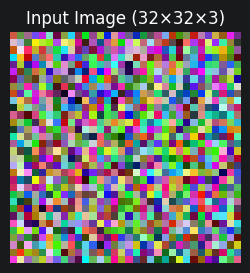

<Figure size 1000x600 with 0 Axes>

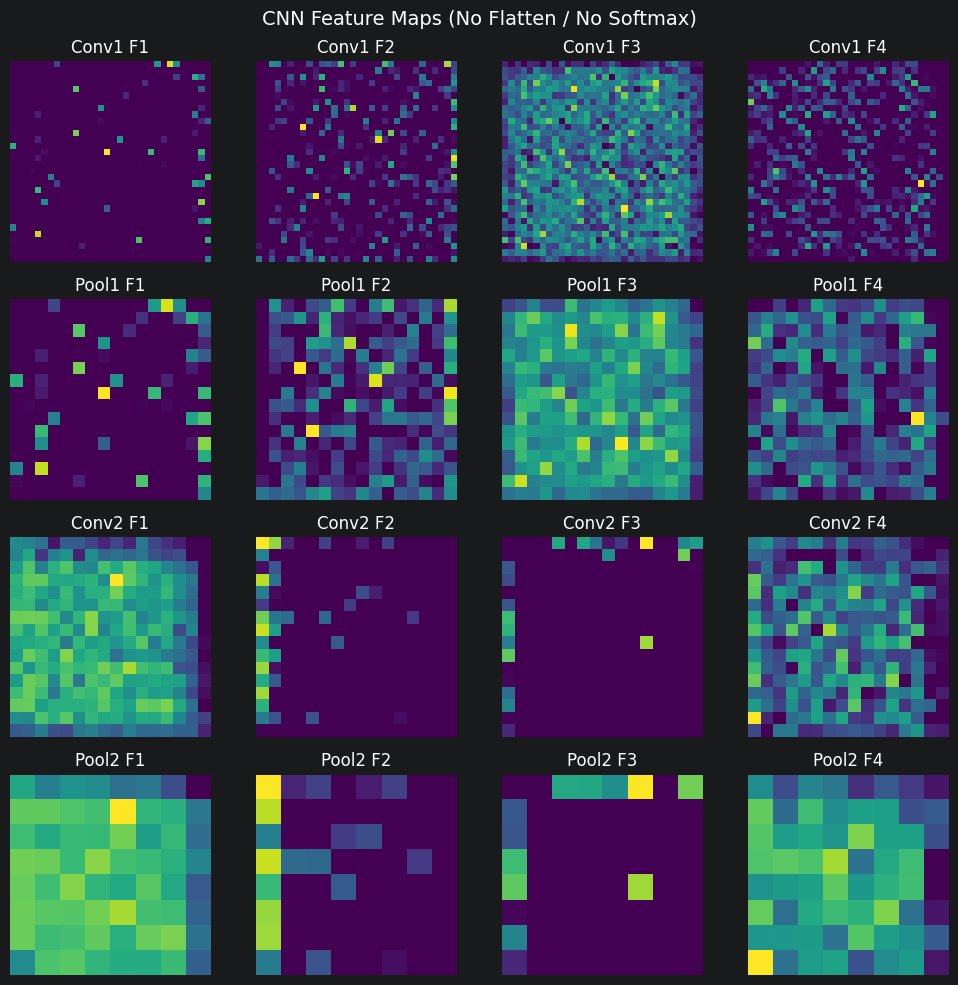

In [30]:
class NumpyCNN:
    def __init__(self):
        self.conv1_kernels = np.random.randn(4, 5, 5, 3).astype(np.float32) * 0.1
        self.conv2_kernels = np.random.randn(4, 5, 5, 4).astype(np.float32) * 0.1
        self.mlp_weights = None
        self.mlp_biases = None
    
    def forward(self, image, verbose=True):
        intermediates = {}
        
        if verbose:
            print(f"Input:      {image.shape}")

        conv1_out = convolution_layer(image, self.conv1_kernels, stride=1, padding=2, activation='relu')
        intermediates['conv1'] = conv1_out
        if verbose:
            print(f"Conv1:      {conv1_out.shape}  (4 kernels 5×5, ReLU, same padding)")
        
        pool1_out = pooling_layer(conv1_out, pool_size=2, stride=2, mode='max')
        intermediates['pool1'] = pool1_out
        if verbose:
            print(f"MaxPool1:   {pool1_out.shape}  (2×2, stride 2)")
        
        conv2_out = convolution_layer(pool1_out, self.conv2_kernels, stride=1, padding=2, activation='relu')
        intermediates['conv2'] = conv2_out
        if verbose:
            print(f"Conv2:      {conv2_out.shape}  (4 kernels 5×5×4, ReLU, same padding)")
        
        pool2_out = pooling_layer(conv2_out, pool_size=2, stride=2, mode='max')
        intermediates['pool2'] = pool2_out
        if verbose:
            print(f"MaxPool2:   {pool2_out.shape}  (2×2, stride 2)")
        
        flat = flatten_function(pool2_out)
        intermediates['flatten'] = flat
        if verbose:
            print(f"Flatten:    {flat.shape}   (identity mapping)")
        
        input_size = flat.shape[0]
        if self.mlp_weights is None:
            self.mlp_weights = [
                np.random.randn(input_size, 49).astype(np.float32) * np.sqrt(2.0 / input_size),
                np.random.randn(49, 10).astype(np.float32) * np.sqrt(2.0 / 49)
            ]
            self.mlp_biases = [
                np.zeros(49).astype(np.float32),
                np.zeros(10).astype(np.float32)
            ]
        
        logits, probs = mlp(flat, hidden_sizes=[49], output_size=10, activation='relu',
                            weights=self.mlp_weights, biases=self.mlp_biases)
        intermediates['logits'] = logits
        intermediates['probs'] = probs
        if verbose:
            print(f"MLP Out:    {probs.shape}   (hidden=49, output=10, ReLU + softmax)")
        
        return logits, probs, intermediates


np.random.seed(42)

cnn = NumpyCNN()
input_image = np.random.rand(32, 32, 3).astype(np.float32)

logits, probs, intermediates = cnn.forward(input_image)

print(f"\n--- Verification ---")
print(f"Input shape:  {input_image.shape} ")
print(f"Output shape: {probs.shape} ")
print(f"Output sums to 1: {probs.sum():.6f} ")
print(f"Predicted class: {np.argmax(probs)} (probability: {probs.max():.4f})")

print("\nIntermediate shapes:")
for k, v in intermediates.items():
    print(f"  {k}: {v.shape}")
print("\nFirst 10 probabilities and logits:")
for i in range(10):
    print(f"  probs[{i}] = {probs[i]:.4f}")

plt.figure(figsize=(3, 3))
plt.imshow(input_image)   # shape (32, 32, 3)
plt.title("Input Image (32×32×3)")
plt.axis('off')
plt.show()

plt.suptitle('Q1(vii): Complete CNN Forward Pass Pipeline', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i in range(4):
    axes[0, i].imshow(intermediates['conv1'][:, :, i], cmap='viridis')
    axes[0, i].set_title(f'Conv1 F{i+1}')
    axes[0, i].axis('off')

for i in range(4):
    axes[1, i].imshow(intermediates['pool1'][:, :, i], cmap='viridis')
    axes[1, i].set_title(f'Pool1 F{i+1}')
    axes[1, i].axis('off')

for i in range(4):
    axes[2, i].imshow(intermediates['conv2'][:, :, i], cmap='viridis')
    axes[2, i].set_title(f'Conv2 F{i+1}')
    axes[2, i].axis('off')

for i in range(4):
    axes[3, i].imshow(intermediates['pool2'][:, :, i], cmap='viridis')
    axes[3, i].set_title(f'Pool2 F{i+1}')
    axes[3, i].axis('off')

plt.suptitle('CNN Feature Maps (No Flatten / No Softmax)', fontsize=14)
plt.tight_layout()
plt.show()

---
# PyTorch Implementation of CNN


In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt
import copy
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## Q2(a):  Train the CNN described in Question 1 (part vii) for image classification using PyTorch. Initialize all network parameters randomly.

In [32]:
class CIFAR10_CNN(nn.Module):
    def __init__(self, dropout_rate=0.0, use_batchnorm=False):
        super(CIFAR10_CNN, self).__init__()
        
        self.conv1 = nn.Conv2d(3, 4, kernel_size=5, stride=1, padding=2)
        self.conv2 = nn.Conv2d(4, 4, kernel_size=5, stride=1, padding=2)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.use_batchnorm = use_batchnorm
        if use_batchnorm:
            self.bn1 = nn.BatchNorm1d(49)
        
        self.fc1 = nn.Linear(8 * 8 * 4, 49)
        self.fc2 = nn.Linear(49, 10) 
        
        self.dropout = nn.Dropout(p=dropout_rate) if dropout_rate > 0 else None
        
        self.activations = {}
    
    def forward(self, x):
        x = self.conv1(x)
        self.activations['conv1'] = x.detach()
        x = F.relu(x)
        x = self.pool(x)
        
        x = self.conv2(x)
        self.activations['conv2'] = x.detach()
        x = F.relu(x)
        x = self.pool(x)
        
        x = x.view(x.size(0), -1)
        self.activations['bottleneck_pre_fc'] = x.detach()
        
        x = self.fc1(x)
        
        if self.use_batchnorm:
            x = self.bn1(x)
        
        x = F.relu(x)
        self.activations['bottleneck'] = x.detach()
        
        if self.dropout is not None:
            x = self.dropout(x)
        
        x = self.fc2(x)
        return x

model = CIFAR10_CNN().to(device)
test_input = torch.randn(1, 3, 32, 32).to(device)
test_output = model(test_input)
print(f"Model architecture:")
print(model)
print(f"\nInput shape:  {test_input.shape}")
print(f"Output shape: {test_output.shape}")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Model architecture:
CIFAR10_CNN(
  (conv1): Conv2d(3, 4, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(4, 4, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=256, out_features=49, bias=True)
  (fc2): Linear(in_features=49, out_features=10, bias=True)
)

Input shape:  torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])
Total parameters: 13,801


## Dataset Preparation

In [34]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

full_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
full_test = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

def get_subset_indices(dataset, num_per_class):
    class_indices = {i: [] for i in range(10)}
    for idx, (_, label) in enumerate(dataset):
        if len(class_indices[label]) < num_per_class:
            class_indices[label].append(idx)
        if all(len(v) >= num_per_class for v in class_indices.values()):
            break
    indices = []
    for i in range(10):
        indices.extend(class_indices[i])
    return indices

train_indices = get_subset_indices(full_train, 100)
test_indices = get_subset_indices(full_test, 10)

train_subset = Subset(full_train, train_indices)
test_subset = Subset(full_test, test_indices)

print(f"Training samples: {len(train_subset)}")
print(f"Test samples: {len(test_subset)}")

100.0%


Training samples: 1000
Test samples: 100


## Q2(b):  Train the CNN described in Question 1 (part vii) for image classification using PyTorch. Initialize all network parameters randomly.

- Vanilla SGD with learning rate η = 0.001.
- Momentum with η = 0.001, α = 0.9.
- RMSProp with η = 0.001, ρ = 0.9.

For training:
- Choose 100 images per class from the training set (total 1000 images).
- Experiment with different mini-batch sizes.
- Shuffle the training data after each epoch.
- Train for 15 epochs (you may experiment with more epochs).

In [35]:
def train_model(model, train_loader, test_loader, optimizer, num_epochs=15, device='cpu'):
    criterion = nn.CrossEntropyLoss()
    history = {
        'train_loss': [], 'test_loss': [],
        'train_acc': [], 'test_acc': [],
        'activation_maps': [],
        'bottleneck_features': {'epoch_1': None, 'epoch_last': None},
        'bottleneck_labels': {'epoch_1': None, 'epoch_last': None}
    }
    
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
        
        train_loss = total_loss / total
        train_acc = 100.0 * correct / total
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        
        model.eval()
        total_loss = 0
        correct = 0
        total = 0
        all_features = []
        all_labels = []
        
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                total_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()
                
                all_features.append(model.activations['bottleneck'].cpu().numpy())
                all_labels.append(labels.cpu().numpy())
        
        test_loss = total_loss / total
        test_acc = 100.0 * correct / total
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)
        
        history['activation_maps'].append({
            'conv1': model.activations.get('conv1', None),
            'conv2': model.activations.get('conv2', None)
        })
        
        features = np.concatenate(all_features, axis=0)
        labels_arr = np.concatenate(all_labels, axis=0)
        
        if epoch == 0:
            history['bottleneck_features']['epoch_1'] = features
            history['bottleneck_labels']['epoch_1'] = labels_arr
        if epoch == num_epochs - 1:
            history['bottleneck_features']['epoch_last'] = features
            history['bottleneck_labels']['epoch_last'] = labels_arr

        print(f"  Epoch {epoch+1:2d}/{num_epochs}: "
                f"Train Loss={train_loss:.4f}, Train Acc={train_acc:.1f}%, "
                f"Test Loss={test_loss:.4f}, Test Acc={test_acc:.1f}%")
    
    return history

In [36]:
batch_size = 32

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_subset, batch_size=batch_size, shuffle=False)

results = {}

optimizer_configs = {
    'Vanilla SGD': lambda m: optim.SGD(m.parameters(), lr=0.001),
    'Momentum': lambda m: optim.SGD(m.parameters(), lr=0.001, momentum=0.9),
    'RMSProp': lambda m: optim.RMSprop(m.parameters(), lr=0.001, alpha=0.9),
}

for opt_name, opt_fn in optimizer_configs.items():
    print(f"Training with {opt_name}")
    model = CIFAR10_CNN().to(device)
    optimizer = opt_fn(model)
    history = train_model(model, train_loader, test_loader, optimizer, num_epochs=15, device=device)
    results[opt_name] = {'history': history, 'model': copy.deepcopy(model)}


Training with Vanilla SGD
  Epoch  1/15: Train Loss=2.3066, Train Acc=10.5%, Test Loss=2.3074, Test Acc=11.0%
  Epoch  2/15: Train Loss=2.3064, Train Acc=10.5%, Test Loss=2.3073, Test Acc=11.0%
  Epoch  3/15: Train Loss=2.3062, Train Acc=10.7%, Test Loss=2.3071, Test Acc=11.0%
  Epoch  4/15: Train Loss=2.3060, Train Acc=10.6%, Test Loss=2.3069, Test Acc=11.0%
  Epoch  5/15: Train Loss=2.3058, Train Acc=10.7%, Test Loss=2.3068, Test Acc=11.0%
  Epoch  6/15: Train Loss=2.3056, Train Acc=10.7%, Test Loss=2.3066, Test Acc=11.0%
  Epoch  7/15: Train Loss=2.3054, Train Acc=10.7%, Test Loss=2.3064, Test Acc=11.0%
  Epoch  8/15: Train Loss=2.3051, Train Acc=10.7%, Test Loss=2.3062, Test Acc=11.0%
  Epoch  9/15: Train Loss=2.3049, Train Acc=10.7%, Test Loss=2.3060, Test Acc=11.0%
  Epoch 10/15: Train Loss=2.3046, Train Acc=11.0%, Test Loss=2.3058, Test Acc=11.0%
  Epoch 11/15: Train Loss=2.3044, Train Acc=11.1%, Test Loss=2.3056, Test Acc=11.0%
  Epoch 12/15: Train Loss=2.3041, Train Acc=11.1%,

## Q2(c): Perform the following after each epoch:

### (c.i) Compute the error on training and test datasets. Use 10 images per class from the test set (total 100 images). Plot training and test error as a function of epochs.

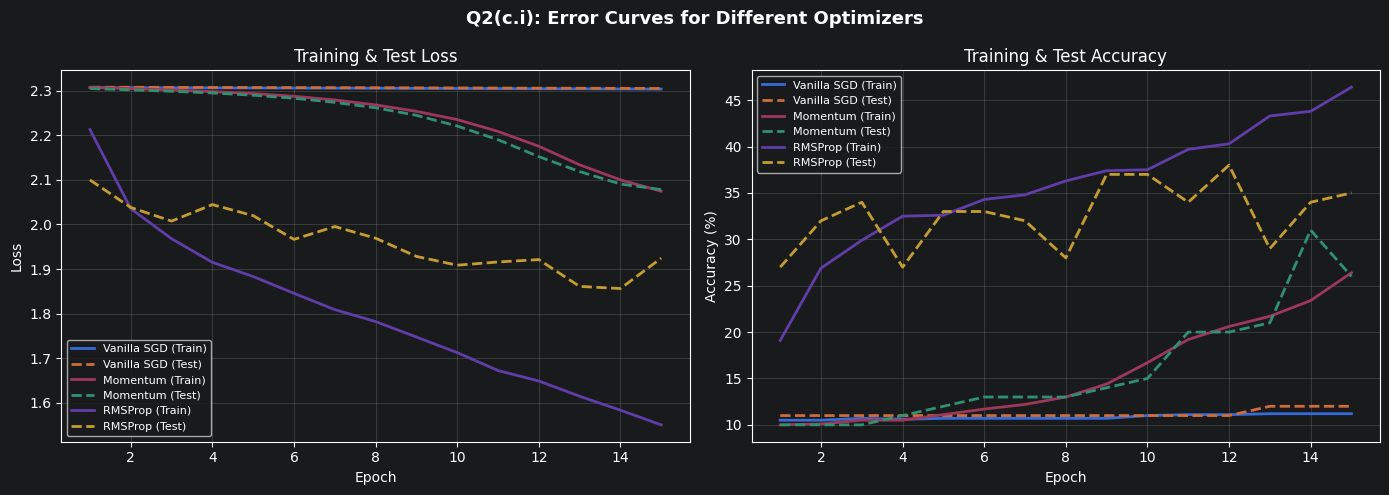

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for opt_name, res in results.items():
    h = res['history']
    epochs = range(1, len(h['train_loss']) + 1)
    
    axes[0].plot(epochs, h['train_loss'], '-', label=f'{opt_name} (Train)', linewidth=2)
    axes[0].plot(epochs, h['test_loss'], '--', label=f'{opt_name} (Test)', linewidth=2)
    
    axes[1].plot(epochs, h['train_acc'], '-', label=f'{opt_name} (Train)', linewidth=2)
    axes[1].plot(epochs, h['test_acc'], '--', label=f'{opt_name} (Test)', linewidth=2)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Test Loss')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Training & Test Accuracy')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Q2(c.i): Error Curves for Different Optimizers', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### (c.ii) Visualize activation maps by selecting representative slices from the activation volumes of each convolution layer.

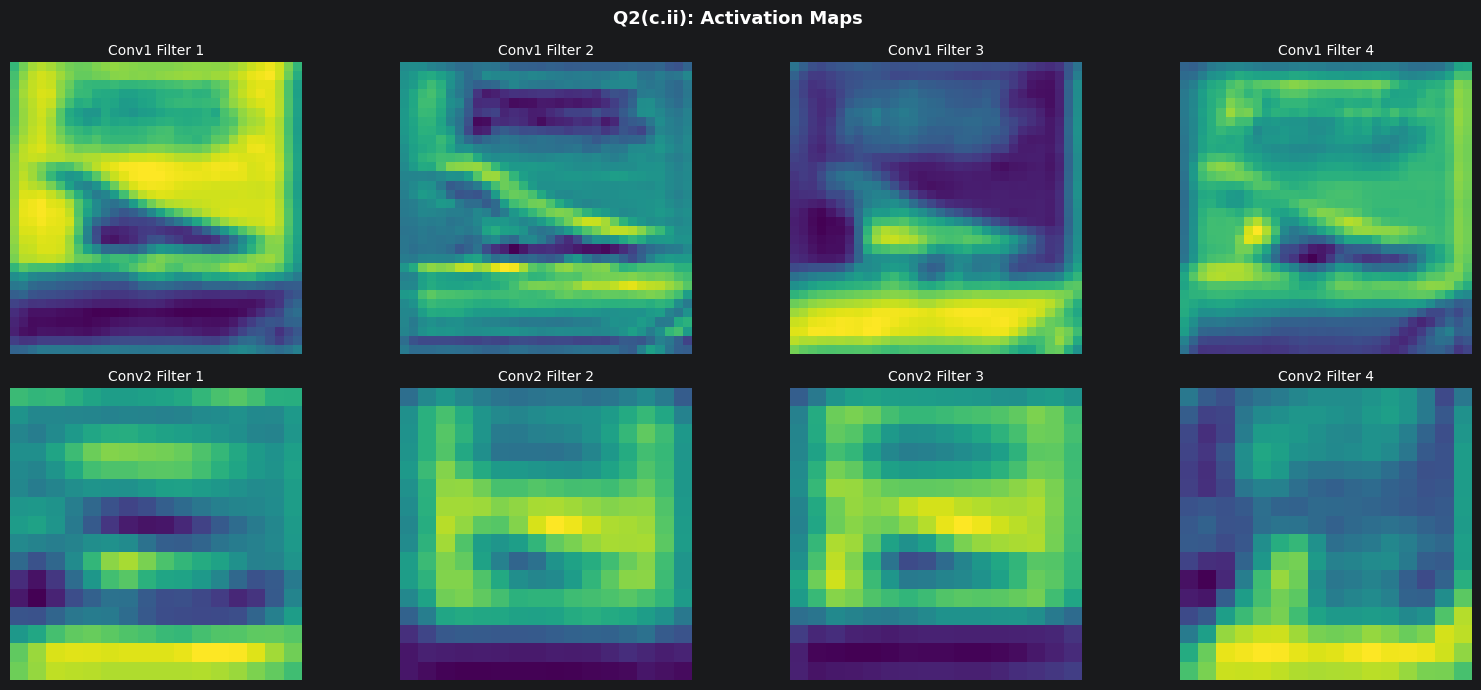

In [38]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

model_vis = results['RMSProp']['model']
model_vis.eval()

sample_img, sample_label = test_subset[0]
with torch.no_grad():
    _ = model_vis(sample_img.unsqueeze(0).to(device))

conv1_maps = model_vis.activations['conv1'][0].cpu().numpy()
conv2_maps = model_vis.activations['conv2'][0].cpu().numpy()

fig.suptitle(f'Q2(c.ii): Activation Maps ', fontsize=13, fontweight='bold')

for i in range(4):
    axes[0, i].imshow(conv1_maps[i])
    axes[0, i].set_title(f'Conv1 Filter {i+1}', fontsize=10)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(conv2_maps[i])
    axes[1, i].set_title(f'Conv2 Filter {i+1}', fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

### (c.iii) Report the classification accuracy.

In [39]:
for opt_name, res in results.items():
    h = res['history']
    print(f"  {opt_name:15s}: Train Acc = {h['train_acc'][-1]:.2f}%, Test Acc = {h['test_acc'][-1]:.2f}%")

  Vanilla SGD    : Train Acc = 11.20%, Test Acc = 12.00%
  Momentum       : Train Acc = 26.40%, Test Acc = 26.00%
  RMSProp        : Train Acc = 46.40%, Test Acc = 35.00%


## Q2(d): Use tSNE to visualize the bottleneck feature at the end of the first epoch and the last epoch. Use the same set of test images as in the previous question.

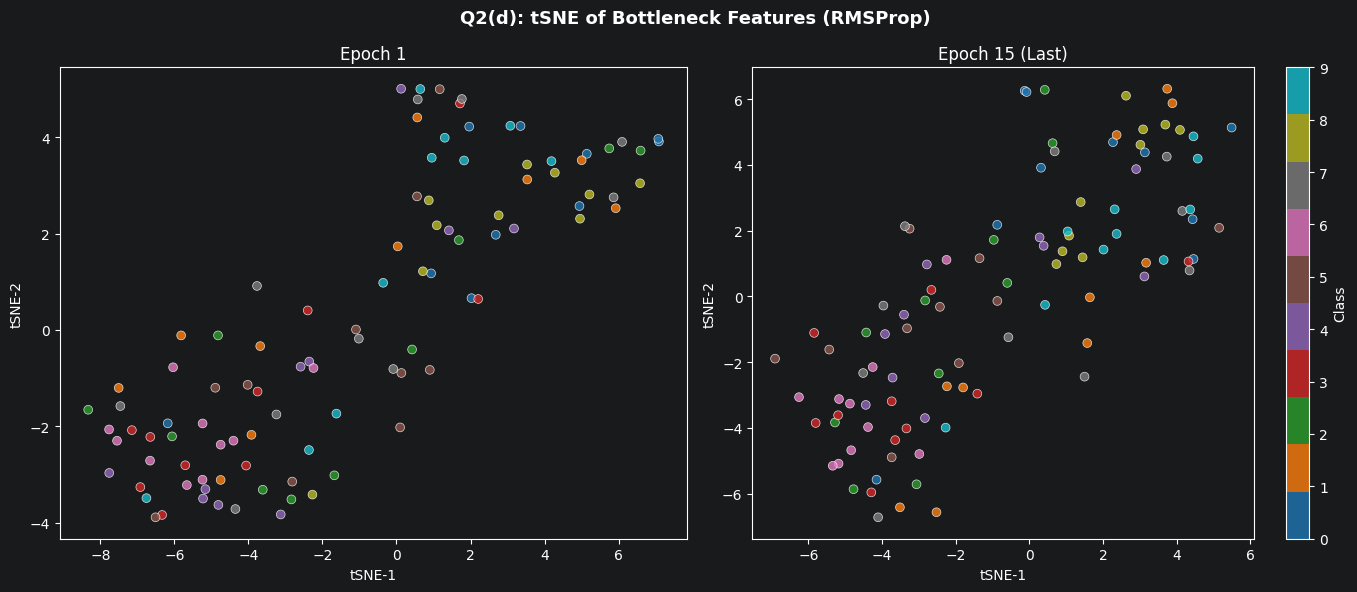

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for idx, (key, title) in enumerate([('epoch_1', 'Epoch 1'), ('epoch_last', 'Epoch 15 (Last)')]):
    features = results['RMSProp']['history']['bottleneck_features'][key]
    labels = results['RMSProp']['history']['bottleneck_labels'][key]
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(features)-1))
    features_2d = tsne.fit_transform(features)
    
    scatter = axes[idx].scatter(features_2d[:, 0], features_2d[:, 1], 
                                c=labels, cmap='tab10', s=40, alpha=0.8, edgecolors='white', linewidth=0.5)
    axes[idx].set_title(title, fontsize=12)
    axes[idx].set_xlabel('tSNE-1')
    axes[idx].set_ylabel('tSNE-2')

plt.colorbar(scatter, ax=axes[1], label='Class')
plt.suptitle('Q2(d): tSNE of Bottleneck Features (RMSProp)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Q2(e): Apply dropout at the hidden layer of the MLP with dropout rates p = 0.2, 0.5, 0.8. Train using RMSProp and report results. Compare performance with the model without dropout and comment on differences in training and testing performance.
 

Training with Dropout No Dropout
  Epoch  1/15: Train Loss=2.2166, Train Acc=16.8%, Test Loss=2.1173, Test Acc=22.0%
  Epoch  2/15: Train Loss=2.0512, Train Acc=25.4%, Test Loss=2.0668, Test Acc=26.0%
  Epoch  3/15: Train Loss=1.9700, Train Acc=29.4%, Test Loss=2.0134, Test Acc=29.0%
  Epoch  4/15: Train Loss=1.9179, Train Acc=31.5%, Test Loss=1.9986, Test Acc=34.0%
  Epoch  5/15: Train Loss=1.8768, Train Acc=35.0%, Test Loss=1.9982, Test Acc=33.0%
  Epoch  6/15: Train Loss=1.8290, Train Acc=36.3%, Test Loss=1.9671, Test Acc=30.0%
  Epoch  7/15: Train Loss=1.7798, Train Acc=38.3%, Test Loss=1.9646, Test Acc=37.0%
  Epoch  8/15: Train Loss=1.7350, Train Acc=40.1%, Test Loss=1.9437, Test Acc=33.0%
  Epoch  9/15: Train Loss=1.6960, Train Acc=40.8%, Test Loss=1.8921, Test Acc=35.0%
  Epoch 10/15: Train Loss=1.6495, Train Acc=43.2%, Test Loss=1.8957, Test Acc=39.0%
  Epoch 11/15: Train Loss=1.6152, Train Acc=44.0%, Test Loss=2.0975, Test Acc=32.0%
  Epoch 12/15: Train Loss=1.5841, Train Acc

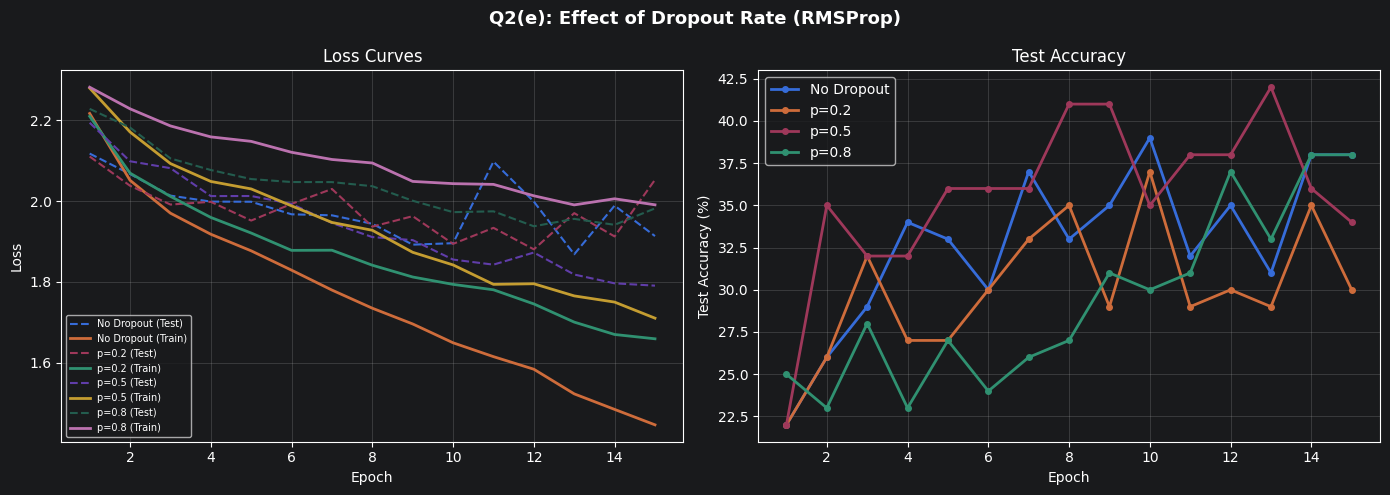


Final Test Accuracies:
  No Dropout     : 38.00%
  p=0.2          : 30.00%
  p=0.5          : 34.00%
  p=0.8          : 38.00%


In [41]:
dropout_results = {}

for p in [0.0, 0.2, 0.5, 0.8]:
    label = f'p={p}' if p > 0 else 'No Dropout'
    print(f"Training with Dropout {label}")
    
    model = CIFAR10_CNN(dropout_rate=p).to(device)
    optimizer = optim.RMSprop(model.parameters(), lr=0.001, alpha=0.9)
    history = train_model(model, train_loader, test_loader, optimizer, num_epochs=15, device=device)
    dropout_results[label] = history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, h in dropout_results.items():
    epochs = range(1, len(h['train_loss']) + 1)
    axes[0].plot(epochs, h['test_loss'], '--',  label=f'{label} (Test)', linewidth=1.5)
    axes[0].plot(epochs, h['train_loss'], '-',  label=f'{label} (Train)', linewidth=2)
    axes[1].plot(epochs, h['test_acc'], '-o', label=label, linewidth=2, markersize=4)

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curves'); axes[0].legend(fontsize=7); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Test Accuracy (%)')
axes[1].set_title('Test Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('Q2(e): Effect of Dropout Rate (RMSProp)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nFinal Test Accuracies:")
for label, h in dropout_results.items():
    print(f"  {label:15s}: {h['test_acc'][-1]:.2f}%")

## Q2(f): Introduce batch normalization (BN) at the hidden layer of the MLP and report the performance. Batch normalization should be applied at the output of the hidden layer before applying the non-linearity. In your implementation, include both BN and dropout (with p = 0.2). Compare the performance with the vanilla implementation as well as the model with only dropout, and comment on the training and testing performance.
 

Training: Vanilla
  Epoch  1/15: Train Loss=2.2688, Train Acc=14.9%, Test Loss=2.2195, Test Acc=17.0%
  Epoch  2/15: Train Loss=2.1402, Train Acc=21.1%, Test Loss=2.0915, Test Acc=27.0%
  Epoch  3/15: Train Loss=2.0197, Train Acc=27.2%, Test Loss=2.0091, Test Acc=29.0%
  Epoch  4/15: Train Loss=1.9205, Train Acc=30.8%, Test Loss=2.0221, Test Acc=28.0%
  Epoch  5/15: Train Loss=1.8556, Train Acc=33.1%, Test Loss=2.0203, Test Acc=22.0%
  Epoch  6/15: Train Loss=1.8104, Train Acc=36.5%, Test Loss=1.9587, Test Acc=32.0%
  Epoch  7/15: Train Loss=1.7551, Train Acc=37.3%, Test Loss=1.9015, Test Acc=34.0%
  Epoch  8/15: Train Loss=1.6926, Train Acc=38.6%, Test Loss=1.8900, Test Acc=32.0%
  Epoch  9/15: Train Loss=1.6657, Train Acc=38.8%, Test Loss=1.9009, Test Acc=34.0%
  Epoch 10/15: Train Loss=1.6210, Train Acc=43.3%, Test Loss=1.9485, Test Acc=33.0%
  Epoch 11/15: Train Loss=1.5840, Train Acc=43.8%, Test Loss=1.8886, Test Acc=34.0%
  Epoch 12/15: Train Loss=1.5336, Train Acc=45.6%, Test Lo

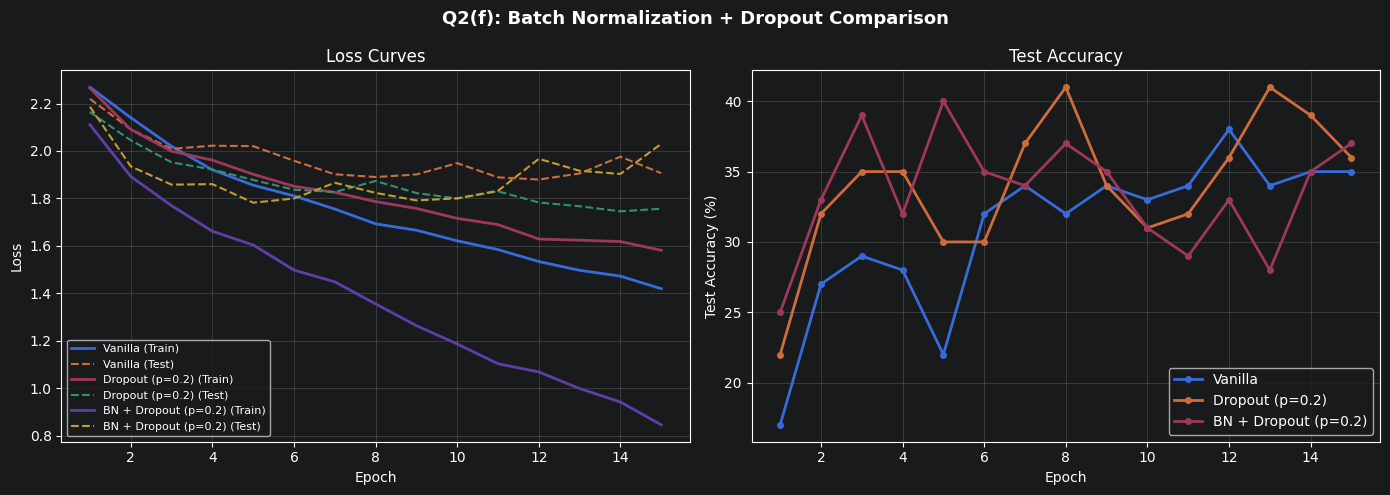


Final Results:
  Vanilla                  : Train Acc=49.20%, Test Acc=35.00%
  Dropout (p=0.2)          : Train Acc=42.90%, Test Acc=36.00%
  BN + Dropout (p=0.2)     : Train Acc=75.50%, Test Acc=37.00%


In [42]:
bn_results = {}

configs = {
    'Vanilla': {'dropout_rate': 0.0, 'use_batchnorm': False},
    'Dropout (p=0.2)': {'dropout_rate': 0.2, 'use_batchnorm': False},
    'BN + Dropout (p=0.2)': {'dropout_rate': 0.2, 'use_batchnorm': True},
}

for label, cfg in configs.items():
    print(f"Training: {label}")
    
    model = CIFAR10_CNN(**cfg).to(device)
    optimizer = optim.RMSprop(model.parameters(), lr=0.001, alpha=0.9)
    history = train_model(model, train_loader, test_loader, optimizer, num_epochs=15, device=device)
    bn_results[label] = history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, h in bn_results.items():
    epochs = range(1, len(h['train_loss']) + 1)
    axes[0].plot(epochs, h['train_loss'], '-',  label=f'{label} (Train)', linewidth=2)
    axes[0].plot(epochs, h['test_loss'], '--',  label=f'{label} (Test)', linewidth=1.5)
    axes[1].plot(epochs, h['test_acc'], '-o', label=label, linewidth=2, markersize=4)

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curves'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Test Accuracy (%)')
axes[1].set_title('Test Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('Q2(f): Batch Normalization + Dropout Comparison', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nFinal Results:")
for label, h in bn_results.items():
    print(f"  {label:25s}: Train Acc={h['train_acc'][-1]:.2f}%, Test Acc={h['test_acc'][-1]:.2f}%")

### Q2(f) Observations

**Batch Normalization** typically:
- Accelerates convergence by normalizing layer outputs
- Acts as a regularizer (reduces need for dropout)
- Allows use of higher learning rates

When combined with dropout (p=0.2):
- Usually achieves best generalization
- Training may be slightly slower per epoch but converges faster in terms of epochs
- Provides complementary regularization effects

---
# Question 3: Backpropagation in CNN (Theory)

The input is an 8 × 8 grayscale image X.
- A 3 × 3 convolutional filter with bias, stride = 1, and padding = 1 is applied to produce feature map
Z1 .
- A ReLU activation is applied to obtain A1.
- A 2 × 2 max-pooling layer with stride = 2 is applied to obtain P1 .
- A second 3×3 convolutional layer with 2 filters, stride = 1, and no padding is applied on P1 , producing
Z2 .
- A ReLU activation is applied to obtain A2.
- The feature maps are flattened into a vector F , which is passed through a fully connected layer (with
weights W , bias b) to produce Z3.
- A Sigmoid activation is applied to obtain the final output ŷ.
- The network is trained using binary cross-entropy (BCE) loss.

## Q3(i):  Draw a clear flow diagram of the network described above.

```
X (8×8×1) 
  │
  ├── Conv1 (3×3, stride=1, pad=1, bias) 
  │     \|/
  │   Z₁ (8×8×1)
  │     \|/
  │   ReLU
  │     \|/
  │   A₁ (8×8×1)
  │     \|/
  │   MaxPool (2×2, stride=2)
  │     \|/
  │   P₁ (4×4×1)
  │     \|/
  ├── Conv2 (3×3, 2 filters, stride=1, no padding, bias)
  │     \|/
  │   Z₂ (2×2×2)
  │     \|/
  │   ReLU
  │     \|/
  │   A₂ (2×2×2)
  │     \|/
  │   Flatten
  │     \|/
  │   F (8×1)
  │     \|/
  ├── FC (W: 1×8, b: 1×1)
  │     \|/
  │   Z₃ (1×1)
  │     \|/
  │   Sigmoid
  │     \|/
  │   ŷ (scalar)
  │     \|/
  └── BCE Loss: L = -(y log(ŷ) + (1-y) log(1-ŷ))
```

## Q3(ii): Determine the dimensions of the following Z1, A1, P1, Z2, A2, F, Z3, ŷ

Given input $X$ is $8 \times 8 \times 1$ (grayscale):

| Layer | Formula | Dimensions |
|-------|---------|------------|
| $Z_1$ | Conv(3×3, stride=1, pad=1): $\frac{8 + 2(1) - 3}{1} + 1 = 8$ | $8 \times 8 \times 1$ |
| $A_1$ | ReLU($Z_1$) | $8 \times 8 \times 1$ |
| $P_1$ | MaxPool(2×2, stride=2): $\frac{8-2}{2}+1=4$ | $4 \times 4 \times 1$ |
| $Z_2$ | Conv(3×3, 2 filters, stride=1, no pad): $\frac{4-3}{1}+1=2$ | $2 \times 2 \times 2$ |
| $A_2$ | ReLU($Z_2$) | $2 \times 2 \times 2$ |
| $F$ | Flatten($A_2$): $2 \times 2 \times 2 = 8$ | $8 \times 1$ |
| $Z_3$ | $WF + b$ | $1 \times 1$ (scalar) |
| $\hat{y}$ | $\sigma(Z_3)$ | $1 \times 1$ (scalar) |

## Q3(iii): Compute the total number of trainable parameters in the network .

| Layer | Parameters | Count |
|-------|-----------|-------|
| Conv1 | 1 filter of $3 \times 3 \times 1$ + 1 bias | $9 + 1 = 10$ |
| Conv2 | 2 filters of $3 \times 3 \times 1$ + 2 biases | $2 \times 9 + 2 = 20$ |
| FC | Weight $W \in \mathbb{R}^{1 \times 8}$ + bias $b \in \mathbb{R}^{1}$ | $8 + 1 = 9$ |
| **Total** | | **39** |

## Q3(iv):  Using backpropagation, derive the gradients of the loss with respect to:

### Loss Function

Binary Cross-Entropy:
$$L = -\left[y \log(\hat{y}) + (1 - y) \log(1 - \hat{y})\right]$$

### Starting gradient:

$$\frac{\partial L}{\partial \hat{y}} = -\frac{y}{\hat{y}} + \frac{1-y}{1-\hat{y}} = \frac{\hat{y} - y}{\hat{y}(1-\hat{y})}$$

### Through Sigmoid:

Since $\hat{y} = \sigma(Z_3)$ and $\sigma'(Z_3) = \hat{y}(1-\hat{y})$:

$$\frac{\partial L}{\partial Z_3} = \frac{\partial L}{\partial \hat{y}} \cdot \sigma'(Z_3) = \frac{\hat{y} - y}{\hat{y}(1-\hat{y})} \cdot \hat{y}(1-\hat{y}) = \hat{y} - y$$

---

### (a) Fully connected layer parameters (W, b)

Given $Z_3 = WF + b$:

$$\frac{\partial L}{\partial W} = \frac{\partial L}{\partial Z_3} \cdot F^T = (\hat{y} - y) \cdot F^T$$

$$\frac{\partial L}{\partial b} = \frac{\partial L}{\partial Z_3} = \hat{y} - y$$

$$\frac{\partial L}{\partial F} = W^T \cdot \frac{\partial L}{\partial Z_3} = W^T (\hat{y} - y)$$

This gives us $\frac{\partial L}{\partial F} \in \mathbb{R}^{8 \times 1}$.

---

### (b) Second convolutional layer parameters

**Step 1: Reshape gradient back to volume**

$$\frac{\partial L}{\partial A_2} = \text{reshape}\left(\frac{\partial L}{\partial F}\right) \in \mathbb{R}^{2 \times 2 \times 2}$$

**Step 2: Through ReLU**

$$\frac{\partial L}{\partial Z_{2}} = \frac{\partial L}{\partial A_{2}} \odot \mathbb{1}[Z_{2} > 0]$$

**Step 3: Conv2 gradient w.r.t. filters**

For Conv2 with input $P_1$ (4×4×1), output $Z_2$ (2×2×2):

For the $k$-th filter ($k = 1, 2$), $W_2^{(k)} \in \mathbb{R}^{3 \times 3 \times 1}$:

$$\frac{\partial L}{\partial W_2^{(k)}[i,j]} = \sum_{m=0}^{1} \sum_{n=0}^{1} \frac{\partial L}{\partial Z_2^{(k)}[m,n]} \cdot P_1[m+i, n+j]$$

In matrix form: this is the cross-correlation of $P_1$ with $\frac{\partial L}{\partial Z_2^{(k)}}$.

$$\frac{\partial L}{\partial W_2^{(k)}} = P_1 \star \frac{\partial L}{\partial Z_2^{(k)}}$$

**Step 4: Conv2 bias gradient**

$$\frac{\partial L}{\partial b_2^{(k)}} = \sum_{m,n} \frac{\partial L}{\partial Z_2^{(k)}[m,n]}$$

---

### (c) First convolutional layer parameters

**Step 1: Gradient w.r.t. Conv2 input ($P_1$)**

For each filter $k$:
$$\frac{\partial L}{\partial P_1} = \sum_{k=1}^{2} \text{FullConv}\left(\frac{\partial L}{\partial Z_2^{(k)}}, \text{rot180}(W_2^{(k)})\right)$$

Result: $\frac{\partial L}{\partial P_1} \in \mathbb{R}^{4 \times 4 \times 1}$

**Step 2: Through Max Pooling (backward)**

The max pooling backward distributes the gradient to the position of the maximum value in each pooling window:

$$\frac{\partial L}{\partial A_1[i,j]} = \begin{cases} \frac{\partial L}{\partial P_1[m,n]} & \text{if } A_1[i,j] \text{ was the max in pool window } (m,n) \\ 0 & \text{otherwise} \end{cases}$$

Result: $\frac{\partial L}{\partial A_1} \in \mathbb{R}^{8 \times 8 \times 1}$ (upsampled, sparse)

**Step 3: Through ReLU**

$$\frac{\partial L}{\partial Z_1} = \frac{\partial L}{\partial A_1} \odot \mathbb{1}[Z_1 > 0]$$

**Step 4: Conv1 filter gradient**

For the single filter $W_1 \in \mathbb{R}^{3 \times 3 \times 1}$:

$$\frac{\partial L}{\partial W_1[i,j]} = \sum_{m=0}^{7} \sum_{n=0}^{7} \frac{\partial L}{\partial Z_1[m,n]} \cdot X_{\text{pad}}[m+i, n+j]$$

where $X_{\text{pad}}$ is the zero-padded input (pad=1 gives $10 \times 10$).

$$\frac{\partial L}{\partial W_1} = X_{\text{pad}} \star \frac{\partial L}{\partial Z_1}$$

**Step 5: Conv1 bias gradient**

$$\frac{\partial L}{\partial b_1} = \sum_{m,n} \frac{\partial L}{\partial Z_1[m,n]}$$


---
# Question 4

## Part 0: Dataset, Input Representation, and Evaluation Protocol

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import re, os
from sklearn.metrics import f1_score, accuracy_score
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

IMDB_DIR = './aclImdb'

def load_imdb_from_dir(base_dir):
    data = {}
    for split in ['train', 'test']:
        texts, labels = [], []
        for label_dir, label_val in [('pos', 1), ('neg', 0)]:
            dir_path = os.path.join(base_dir, split, label_dir)
            if not os.path.exists(dir_path):
                raise FileNotFoundError(
                    f"Directory not found: {dir_path}\n"
                )
            for fname in sorted(os.listdir(dir_path)):
                if fname.endswith('.txt'):
                    with open(os.path.join(dir_path, fname), 'r', encoding='utf-8') as f:
                        texts.append(f.read())
                    labels.append(label_val)
        combined = list(zip(texts, labels))
        np.random.shuffle(combined)
        texts, labels = zip(*combined)
        texts, labels = list(texts), list(labels)
        
        data[split] = (texts, labels)
    return data

imdb_data = load_imdb_from_dir(IMDB_DIR)
train_texts, train_labels = imdb_data['train']
test_texts, test_labels = imdb_data['test']

print(f"Loaded IMDb dataset from: {IMDB_DIR}")
print(f"Train samples: {len(train_texts)} (pos: {sum(train_labels)}, neg: {len(train_labels)-sum(train_labels)})")
print(f"Test samples:  {len(test_texts)} (pos: {sum(test_labels)}, neg: {len(test_labels)-sum(test_labels)})")

Loaded IMDb dataset from: ./aclImdb
Train samples: 25000 (pos: 12500, neg: 12500)
Test samples:  25000 (pos: 12500, neg: 12500)


In [44]:
def clean_text(text):
    text = text.lower()
    return text

def build_vocabulary(texts, max_vocab=5000):
    word_counts = Counter()
    for text in texts:
        words = clean_text(text).split()
        word_counts.update(words)

    vocab = {'<PAD>': 0, '<UNK>': 1}
    for word, _ in word_counts.most_common(max_vocab - 2):
        vocab[word] = len(vocab)
    return vocab

def texts_to_sequences(texts, vocab, max_len=100):
    sequences = []
    for text in texts:
        words = clean_text(text).split()
        seq = [vocab.get(w, 1) for w in words]
        if len(seq) > max_len:
            seq = seq[:max_len]
        else:
            seq = seq + [0] * (max_len - len(seq))
        sequences.append(seq)
    return np.array(sequences)

NUM_TRAIN = 2000
NUM_TEST = 500
MAX_VOCAB = 5000

vocab = build_vocabulary(train_texts[:NUM_TRAIN], max_vocab=MAX_VOCAB)
VOCAB_SIZE = len(vocab)

print(f"Vocabulary size: {VOCAB_SIZE}")
print(f"Using {NUM_TRAIN} train, {NUM_TEST} test samples")

Vocabulary size: 5000
Using 2000 train, 500 test samples


In [45]:
def get_onehot_batch(sequences, vocab_size):
    batch_size, seq_len = sequences.shape
    onehot = np.zeros((batch_size, seq_len, vocab_size), dtype=np.float32)
    for i in range(batch_size):
        for t in range(seq_len):
            if sequences[i, t] < vocab_size:
                onehot[i, t, sequences[i, t]] = 1.0
    return onehot

class EmbeddingLayer:
    def __init__(self, vocab_size, embed_dim):
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.E = np.random.randn(vocab_size, embed_dim).astype(np.float32) * 0.01
    
    def forward(self, sequences):
        return self.E[sequences]
    
    def backward(self, sequences, grad_embed):
        grad_E = np.zeros_like(self.E)
        batch_size, seq_len, _ = grad_embed.shape
        for i in range(batch_size):
            for t in range(seq_len):
                grad_E[sequences[i, t]] += grad_embed[i, t]
        return grad_E


##  Part 1: Vanilla RNN and the Forward Pass
 

In [46]:
class VanillaRNN:
    def __init__(self, input_size, hidden_size, output_size):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        
        scale_xh = np.sqrt(2.0 / (input_size + hidden_size))
        scale_hh = np.sqrt(2.0 / (hidden_size + hidden_size))
        scale_hy = np.sqrt(2.0 / (hidden_size + output_size))
        
        self.Wxh = np.random.randn(input_size, hidden_size).astype(np.float32) * scale_xh
        self.Whh = np.random.randn(hidden_size, hidden_size).astype(np.float32) * scale_hh
        self.bh = np.zeros(hidden_size, dtype=np.float32)
        
        self.Why = np.random.randn(hidden_size, output_size).astype(np.float32) * scale_hy
        self.by = np.zeros(output_size, dtype=np.float32)
    
    def forward(self, x):
        seq_len = x.shape[0]
        
        h = np.zeros(self.hidden_size, dtype=np.float32)
        
        hs = {0: h.copy()}
        
        for t in range(seq_len):
            h = np.tanh(x[t] @ self.Wxh + h @ self.Whh + self.bh)
            hs[t + 1] = h.copy()
        logits = h @ self.Why + self.by
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / exp_logits.sum()
        cache = {'hs': hs, 'x': x, 'probs': probs, 'logits': logits}
        return probs, cache

    def get_params(self):
        return [self.Wxh, self.Whh, self.bh, self.Why, self.by]
    def set_params(self, params):
        self.Wxh, self.Whh, self.bh, self.Why, self.by = params

print("Part 1: Vanilla RNN Forward Pass")
EMBED_DIM = 64
HIDDEN_SIZE = 128
OUTPUT_SIZE = 2
MAX_LEN = 50
rnn = VanillaRNN(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE)
sample_seq = np.random.randn(MAX_LEN, EMBED_DIM).astype(np.float32)
probs, cache = rnn.forward(sample_seq)

print(f"Input shape:  ({MAX_LEN}, {EMBED_DIM})")
print(f"Hidden size:  {HIDDEN_SIZE}")
print(f"Output probs: {probs}")
print(f"Probs sum:    {probs.sum():.6f}")
print(f"Predicted:    {'Positive' if np.argmax(probs) == 1 else 'Negative'}")

Part 1: Vanilla RNN Forward Pass
Input shape:  (50, 64)
Hidden size:  128
Output probs: [0.3089027 0.6910973]
Probs sum:    1.000000
Predicted:    Positive


## Part 2: Backpropagation Through Time (BPTT) and Gradient Issues 


In [47]:
def cross_entropy_loss(probs, label):
    return -np.log(probs[label] + 1e-12)

def bptt(rnn, cache, label, clip_value=5.0):
    hs = cache['hs']
    x = cache['x']
    probs = cache['probs']
    seq_len = x.shape[0]
    
    dWxh = np.zeros_like(rnn.Wxh)
    dWhh = np.zeros_like(rnn.Whh)
    dbh = np.zeros_like(rnn.bh)
    dWhy = np.zeros_like(rnn.Why)
    dby = np.zeros_like(rnn.by)
    
    dy = probs.copy()
    dy[label] -= 1.0
    
    dWhy = np.outer(hs[seq_len], dy)  
    dby = dy.copy()
    
    dh = dy @ rnn.Why.T 
    
    for t in reversed(range(seq_len)):
        h_t = hs[t + 1]
        h_prev = hs[t]
        
        dtanh = dh * (1 - h_t ** 2)
        
        dWxh += np.outer(x[t], dtanh)
        dWhh += np.outer(h_prev, dtanh)
        dbh += dtanh
        
        dh = dtanh @ rnn.Whh.T
    
    grads = {'Wxh': dWxh, 'Whh': dWhh, 'bh': dbh, 'Why': dWhy, 'by': dby}
    
    total_norm = 0
    for g in grads.values():
        total_norm += np.sum(g ** 2)
    total_norm = np.sqrt(total_norm)
    
    if total_norm > clip_value:
        scale = clip_value / total_norm
        for key in grads:
            grads[key] *= scale
    
    return grads, total_norm

probs, cache = rnn.forward(sample_seq)
grads, grad_norm = bptt(rnn, cache, label=1)

print("Part 2: BPTT Gradient Computation")
for name, g in grads.items():
    print(f"  d{name:4s}: shape={str(g.shape):15s}, norm={np.linalg.norm(g):.6f}")
print(f"  Total gradient norm: {grad_norm:.6f}")

Part 2: BPTT Gradient Computation
  dWxh : shape=(64, 128)      , norm=3.184592
  dWhh : shape=(128, 128)     , norm=2.852354
  dbh  : shape=(128,)         , norm=0.408623
  dWhy : shape=(128, 2)       , norm=2.536856
  dby  : shape=(2,)           , norm=0.346179
  Total gradient norm: 6.309664


In [48]:
class SGDOptimizer:
    def __init__(self, lr=0.001):
        self.lr = lr
    
    def step(self, params, grads):
        for p, g in zip(params, grads):
            p -= self.lr * g

class AdamOptimizer:
    def __init__(self, params, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self.m = [np.zeros_like(p) for p in params]
        self.v = [np.zeros_like(p) for p in params]
    
    def step(self, params, grads):
        self.t += 1
        for i, (p, g) in enumerate(zip(params, grads)):
            self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g
            self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * g ** 2
            m_hat = self.m[i] / (1 - self.beta1 ** self.t)
            v_hat = self.v[i] / (1 - self.beta2 ** self.t)
            p -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

In [49]:
def train_rnn_model(model, embedding, train_seqs, train_labels, test_seqs, test_labels,
                   optimizer_type='adam', lr=0.001, epochs=10, max_len=50, batch_size=32, 
                   clip_value=5.0, verbose=True):
    params = model.get_params()
    
    if optimizer_type == 'adam':
        opt = AdamOptimizer(params + [embedding.E], lr=lr)
    else:
        opt = SGDOptimizer(lr=lr)
    
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': [],
               'train_f1': [], 'test_f1': [], 'grad_norms': []}
    
    N_train = len(train_seqs)
    
    for epoch in range(epochs):
        perm = np.random.permutation(N_train)
        train_seqs_sh = train_seqs[perm]
        train_labels_sh = train_labels[perm]
        
        epoch_loss = 0
        epoch_preds = []
        epoch_true = []
        epoch_gnorms = []
        
        for i in range(N_train):
            seq = train_seqs_sh[i:i+1]
            embedded = embedding.forward(seq)
            x = embedded[0]
            label = train_labels_sh[i]
            
            probs, cache = model.forward(x)
            loss = cross_entropy_loss(probs, label)
            epoch_loss += loss
            epoch_preds.append(np.argmax(probs))
            epoch_true.append(label)
            
            grads, gnorm = bptt(model, cache, label, clip_value)
            epoch_gnorms.append(gnorm)
            
            grad_embed = np.zeros_like(x)
            hs = cache['hs']
            dy = probs.copy()
            dy[label] -= 1.0
            dh = dy @ model.Why.T
            for t in reversed(range(max_len)):
                h_t = hs[t + 1]
                dtanh = dh * (1 - h_t ** 2)
                grad_embed[t] = dtanh @ model.Wxh.T
                dh = dtanh @ model.Whh.T
            
            grad_E = embedding.backward(seq, grad_embed[np.newaxis])
            
            param_grads = [grads['Wxh'], grads['Whh'], grads['bh'], grads['Why'], grads['by']]
            all_params = model.get_params() + [embedding.E]
            all_grads = param_grads + [grad_E]
            
            if optimizer_type == 'adam':
                opt.step(all_params, all_grads)
            else:
                opt.step(all_params, all_grads)
        
        train_loss = epoch_loss / N_train
        train_acc = accuracy_score(epoch_true, epoch_preds)
        train_f1 = f1_score(epoch_true, epoch_preds, average='binary')
        
        test_preds = []
        test_true = []
        test_loss_total = 0
        
        for i in range(len(test_seqs)):
            embedded = embedding.forward(test_seqs[i:i+1])
            x = embedded[0]
            probs, _ = model.forward(x)
            test_loss_total += cross_entropy_loss(probs, test_labels[i])
            test_preds.append(np.argmax(probs))
            test_true.append(test_labels[i])
        
        test_loss = test_loss_total / len(test_seqs)
        test_acc = accuracy_score(test_true, test_preds)
        test_f1 = f1_score(test_true, test_preds, average='binary')
        
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        history['train_f1'].append(train_f1)
        history['test_f1'].append(test_f1)
        history['grad_norms'].append(np.mean(epoch_gnorms))
        
        if verbose:
            print(f"  Epoch {epoch+1:2d}: TrainLoss={train_loss:.4f} TrainAcc={train_acc:.3f} "
                  f"TestLoss={test_loss:.4f} TestAcc={test_acc:.3f} TestF1={test_f1:.3f}")
    
    return history


In [50]:
MAX_LEN = 50
train_seqs = texts_to_sequences(train_texts[:NUM_TRAIN], vocab, max_len=MAX_LEN)
train_labels_arr = np.array(train_labels[:NUM_TRAIN])
test_seqs = texts_to_sequences(test_texts[:NUM_TEST], vocab, max_len=MAX_LEN)
test_labels_arr = np.array(test_labels[:NUM_TEST])

print(f"Train sequences shape: {train_seqs.shape}")
print(f"Test sequences shape:  {test_seqs.shape}")
print("\n")
print("Training Vanilla RNN with Learned Embeddings (Adam)")
embedding_rnn = EmbeddingLayer(VOCAB_SIZE, EMBED_DIM)
vanilla_rnn = VanillaRNN(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE)

rnn_history_embed = train_rnn_model(
    vanilla_rnn, embedding_rnn,
    train_seqs, train_labels_arr, test_seqs, test_labels_arr,
    optimizer_type='adam', lr=0.001, epochs=10, max_len=MAX_LEN
)

print(f"\nFinal Accuracy: {rnn_history_embed['test_acc'][-1]:.4f}, F1: {rnn_history_embed['test_f1'][-1]:.4f}")

Train sequences shape: (2000, 50)
Test sequences shape:  (500, 50)


Training Vanilla RNN with Learned Embeddings (Adam)
  Epoch  1: TrainLoss=0.7957 TrainAcc=0.506 TestLoss=0.6976 TestAcc=0.524 TestF1=0.008
  Epoch  2: TrainLoss=0.8001 TrainAcc=0.529 TestLoss=0.7116 TestAcc=0.560 TestF1=0.484
  Epoch  3: TrainLoss=0.6502 TrainAcc=0.706 TestLoss=1.1382 TestAcc=0.506 TestF1=0.611
  Epoch  4: TrainLoss=0.5405 TrainAcc=0.786 TestLoss=1.4861 TestAcc=0.482 TestF1=0.457
  Epoch  5: TrainLoss=0.4147 TrainAcc=0.853 TestLoss=1.9860 TestAcc=0.506 TestF1=0.327
  Epoch  6: TrainLoss=0.3306 TrainAcc=0.889 TestLoss=1.7779 TestAcc=0.516 TestF1=0.489
  Epoch  7: TrainLoss=0.3060 TrainAcc=0.902 TestLoss=1.8722 TestAcc=0.506 TestF1=0.507
  Epoch  8: TrainLoss=0.2620 TrainAcc=0.915 TestLoss=2.4586 TestAcc=0.518 TestF1=0.528
  Epoch  9: TrainLoss=0.2177 TrainAcc=0.934 TestLoss=2.3990 TestAcc=0.520 TestF1=0.520
  Epoch 10: TrainLoss=0.2068 TrainAcc=0.938 TestLoss=2.5928 TestAcc=0.504 TestF1=0.500

Final Ac

##  Part 3: Long Short-Term Memory (LSTM) Implementation
 
- **Forget Gate:**
- **Input Gate:**
- **Candidate:**
- **Cell Update:**
- **Output Gate:**
- **Hidden State:**

In [51]:
def sigmoid_fn(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

class LSTM:
    
    def __init__(self, input_size, hidden_size, output_size, coupled_gates=False):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.coupled_gates = coupled_gates
        
        concat_size = input_size + hidden_size
        scale = np.sqrt(2.0 / concat_size)

        self.Wf = np.random.randn(concat_size, hidden_size).astype(np.float32) * scale
        self.bf = np.zeros(hidden_size, dtype=np.float32)
        
        self.Wi = np.random.randn(concat_size, hidden_size).astype(np.float32) * scale
        self.bi = np.zeros(hidden_size, dtype=np.float32)
        
        self.Wc = np.random.randn(concat_size, hidden_size).astype(np.float32) * scale
        self.bc = np.zeros(hidden_size, dtype=np.float32)
        
        self.Wo = np.random.randn(concat_size, hidden_size).astype(np.float32) * scale
        self.bo = np.zeros(hidden_size, dtype=np.float32)
        
        self.Why = np.random.randn(hidden_size, output_size).astype(np.float32) * np.sqrt(2.0 / hidden_size)
        self.by = np.zeros(output_size, dtype=np.float32)
    
    def forward(self, x):
        seq_len = x.shape[0]
        h = np.zeros(self.hidden_size, dtype=np.float32)
        C = np.zeros(self.hidden_size, dtype=np.float32)
        
        cache = {'hs': {0: h.copy()}, 'Cs': {0: C.copy()}, 'x': x,
                 'fs': {}, 'is_': {}, 'cs': {}, 'os': {}, 'concats': {}}
        
        for t in range(seq_len):
            concat = np.concatenate([h, x[t]])
            cache['concats'][t] = concat
            
            f_t = sigmoid_fn(concat @ self.Wf + self.bf)
            cache['fs'][t] = f_t
            
            if self.coupled_gates:
                i_t = 1 - f_t
            else:
                i_t = sigmoid_fn(concat @ self.Wi + self.bi)
            cache['is_'][t] = i_t
            
            C_tilde = np.tanh(concat @ self.Wc + self.bc)
            cache['cs'][t] = C_tilde
            
            C = f_t * C + i_t * C_tilde
            cache['Cs'][t + 1] = C.copy()
            
            o_t = sigmoid_fn(concat @ self.Wo + self.bo)
            cache['os'][t] = o_t
            h = o_t * np.tanh(C)
            cache['hs'][t + 1] = h.copy()
        
        logits = h @ self.Why + self.by
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / exp_logits.sum()
        
        cache['probs'] = probs
        return probs, cache
    
    def get_params(self):
        return [self.Wf, self.bf, self.Wi, self.bi, self.Wc, self.bc,
                self.Wo, self.bo, self.Why, self.by]
    
    def set_params(self, params):
        (self.Wf, self.bf, self.Wi, self.bi, self.Wc, self.bc,
         self.Wo, self.bo, self.Why, self.by) = params


def bptt_lstm(lstm, cache, label, clip_value=5.0):
    hs = cache['hs']
    Cs = cache['Cs']
    x = cache['x']
    probs = cache['probs']
    seq_len = x.shape[0]
    
    dWf = np.zeros_like(lstm.Wf)
    dbf = np.zeros_like(lstm.bf)
    dWi = np.zeros_like(lstm.Wi)
    dbi = np.zeros_like(lstm.bi)
    dWc = np.zeros_like(lstm.Wc)
    dbc = np.zeros_like(lstm.bc)
    dWo = np.zeros_like(lstm.Wo)
    dbo = np.zeros_like(lstm.bo)
    dWhy = np.zeros_like(lstm.Why)
    dby = np.zeros_like(lstm.by)
    
    dy = probs.copy()
    dy[label] -= 1.0
    
    dWhy = np.outer(hs[seq_len], dy)
    dby = dy.copy()
    
    dh_next = dy @ lstm.Why.T
    dC_next = np.zeros(lstm.hidden_size, dtype=np.float32)
    
    for t in reversed(range(seq_len)):
        f_t = cache['fs'][t]
        i_t = cache['is_'][t]
        C_tilde = cache['cs'][t]
        o_t = cache['os'][t]
        C_t = Cs[t + 1]
        C_prev = Cs[t]
        concat = cache['concats'][t]
        
        dh = dh_next
        
        tanh_C = np.tanh(C_t)
        dC = dh * o_t * (1 - tanh_C ** 2) + dC_next
        
        do = dh * tanh_C
        do_raw = do * o_t * (1 - o_t)
        dWo += np.outer(concat, do_raw)
        dbo += do_raw
        
        df = dC * C_prev
        df_raw = df * f_t * (1 - f_t)
        dWf += np.outer(concat, df_raw)
        dbf += df_raw
        
        if lstm.coupled_gates:
            di_raw = np.zeros_like(df_raw)
        else:
            di = dC * C_tilde
            di_raw = di * i_t * (1 - i_t)
            dWi += np.outer(concat, di_raw)
            dbi += di_raw
        
        dC_tilde = dC * i_t
        dC_tilde_raw = dC_tilde * (1 - C_tilde ** 2)
        dWc += np.outer(concat, dC_tilde_raw)
        dbc += dC_tilde_raw
        
        dC_next = dC * f_t
        
        d_concat = (do_raw @ lstm.Wo.T + df_raw @ lstm.Wf.T + 
                    di_raw @ lstm.Wi.T + dC_tilde_raw @ lstm.Wc.T)
        dh_next = d_concat[:lstm.hidden_size]
    
    grads = {
        'Wf': dWf, 'bf': dbf, 'Wi': dWi, 'bi': dbi,
        'Wc': dWc, 'bc': dbc, 'Wo': dWo, 'bo': dbo,
        'Why': dWhy, 'by': dby
    }
    
    total_norm = np.sqrt(sum(np.sum(g**2) for g in grads.values()))
    if total_norm > clip_value:
        scale = clip_value / total_norm
        for key in grads:
            grads[key] *= scale
    
    return grads, total_norm


print("Part 3: LSTM Forward Pass Test")

lstm = LSTM(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE)
probs, cache = lstm.forward(sample_seq)
print(f"Output probs: {probs}")
print(f"Probs sum: {probs.sum():.6f}")

grads, gnorm = bptt_lstm(lstm, cache, label=1)
print(f"Gradient norm: {gnorm:.6f}")
for name, g in grads.items():
    print(f"  d{name:4s}: shape={str(g.shape):15s}")

Part 3: LSTM Forward Pass Test
Output probs: [0.45182854 0.54817146]
Probs sum: 1.000000
Gradient norm: 2.448214
  dWf  : shape=(192, 128)     
  dbf  : shape=(128,)         
  dWi  : shape=(192, 128)     
  dbi  : shape=(128,)         
  dWc  : shape=(192, 128)     
  dbc  : shape=(128,)         
  dWo  : shape=(192, 128)     
  dbo  : shape=(128,)         
  dWhy : shape=(128, 2)       
  dby  : shape=(2,)           


In [52]:
def train_lstm_model(model, embedding, train_seqs, train_labels, test_seqs, test_labels,
                     optimizer_type='adam', lr=0.001, epochs=15, max_len=50, clip_value=5.0):

    params = model.get_params()
    
    if optimizer_type == 'adam':
        opt = AdamOptimizer(params + [embedding.E], lr=lr)
    else:
        opt = SGDOptimizer(lr=lr)
    
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': [],
               'train_f1': [], 'test_f1': [], 'grad_norms': []}
    
    N_train = len(train_seqs)
    
    for epoch in range(epochs):
        perm = np.random.permutation(N_train)
        train_seqs_sh = train_seqs[perm]
        train_labels_sh = train_labels[perm]
        
        epoch_loss = 0
        epoch_preds = []
        epoch_true = []
        epoch_gnorms = []
        
        for i in range(N_train):
            seq = train_seqs_sh[i:i+1]
            embedded = embedding.forward(seq)
            x = embedded[0]
            label = train_labels_sh[i]
            
            probs, cache = model.forward(x)
            loss = cross_entropy_loss(probs, label)
            epoch_loss += loss
            epoch_preds.append(np.argmax(probs))
            epoch_true.append(label)            
            grads, gnorm = bptt_lstm(model, cache, label, clip_value)
            epoch_gnorms.append(gnorm)
            grad_E = np.zeros_like(embedding.E)
            
            param_grads = [grads['Wf'], grads['bf'], grads['Wi'], grads['bi'],
                          grads['Wc'], grads['bc'], grads['Wo'], grads['bo'],
                          grads['Why'], grads['by']]
            
            all_params = model.get_params() + [embedding.E]
            all_grads = param_grads + [grad_E]
            
            if optimizer_type == 'adam':
                opt.step(all_params, all_grads)
            else:
                opt.step(all_params, all_grads)

        train_loss = epoch_loss / N_train
        train_acc = accuracy_score(epoch_true, epoch_preds)
        train_f1 = f1_score(epoch_true, epoch_preds, average='binary')
        
        test_preds = []
        test_true = []
        test_loss_total = 0
        for i in range(len(test_seqs)):
            embedded = embedding.forward(test_seqs[i:i+1])
            probs, _ = model.forward(embedded[0])
            test_loss_total += cross_entropy_loss(probs, test_labels[i])
            test_preds.append(np.argmax(probs))
            test_true.append(test_labels[i])
        
        test_loss = test_loss_total / len(test_seqs)
        test_acc = accuracy_score(test_true, test_preds)
        test_f1 = f1_score(test_true, test_preds, average='binary')
        
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        history['train_f1'].append(train_f1)
        history['test_f1'].append(test_f1)
        history['grad_norms'].append(np.mean(epoch_gnorms))

        print(f"  Epoch {epoch+1:2d}: TrainLoss={train_loss:.4f} TrainAcc={train_acc:.3f} "
              f"TestLoss={test_loss:.4f} TestAcc={test_acc:.3f} TestF1={test_f1:.3f}")

    return history

print("Training LSTM with Learned Embeddings (Adam)")

embedding_lstm = EmbeddingLayer(VOCAB_SIZE, EMBED_DIM)
lstm_model = LSTM(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE)

lstm_history = train_lstm_model(
    lstm_model, embedding_lstm,
    train_seqs, train_labels_arr, test_seqs, test_labels_arr,
    optimizer_type='adam', lr=0.001, epochs=15, max_len=MAX_LEN
)

print(f"\nFinal Accuracy: {lstm_history['test_acc'][-1]:.4f}, F1: {lstm_history['test_f1'][-1]:.4f}")

Training LSTM with Learned Embeddings (Adam)
  Epoch  1: TrainLoss=0.6940 TrainAcc=0.502 TestLoss=0.6937 TestAcc=0.478 TestF1=0.647
  Epoch  2: TrainLoss=0.6915 TrainAcc=0.515 TestLoss=0.7095 TestAcc=0.478 TestF1=0.647
  Epoch  3: TrainLoss=0.6979 TrainAcc=0.532 TestLoss=0.6944 TestAcc=0.488 TestF1=0.631
  Epoch  4: TrainLoss=0.6900 TrainAcc=0.522 TestLoss=0.6934 TestAcc=0.510 TestF1=0.574
  Epoch  5: TrainLoss=0.6847 TrainAcc=0.543 TestLoss=0.6946 TestAcc=0.512 TestF1=0.567
  Epoch  6: TrainLoss=0.7072 TrainAcc=0.535 TestLoss=0.6955 TestAcc=0.502 TestF1=0.645
  Epoch  7: TrainLoss=0.6953 TrainAcc=0.512 TestLoss=0.6984 TestAcc=0.484 TestF1=0.645
  Epoch  8: TrainLoss=0.6899 TrainAcc=0.542 TestLoss=0.6941 TestAcc=0.510 TestF1=0.164
  Epoch  9: TrainLoss=0.6973 TrainAcc=0.519 TestLoss=0.6919 TestAcc=0.520 TestF1=0.268
  Epoch 10: TrainLoss=0.7825 TrainAcc=0.502 TestLoss=0.7154 TestAcc=0.478 TestF1=0.647
  Epoch 11: TrainLoss=0.7871 TrainAcc=0.498 TestLoss=0.7089 TestAcc=0.522 TestF1=0.00

## Part 4: Ablation Studies

### Ablation A: The Vanishing Gradient in Action

  T=  5: RNN ||∂L/∂h₁||=0.978555, LSTM approx=1.528927
  T= 20: RNN ||∂L/∂h₁||=0.498936, LSTM approx=1.505822
  T= 50: RNN ||∂L/∂h₁||=0.409771, LSTM approx=1.651376


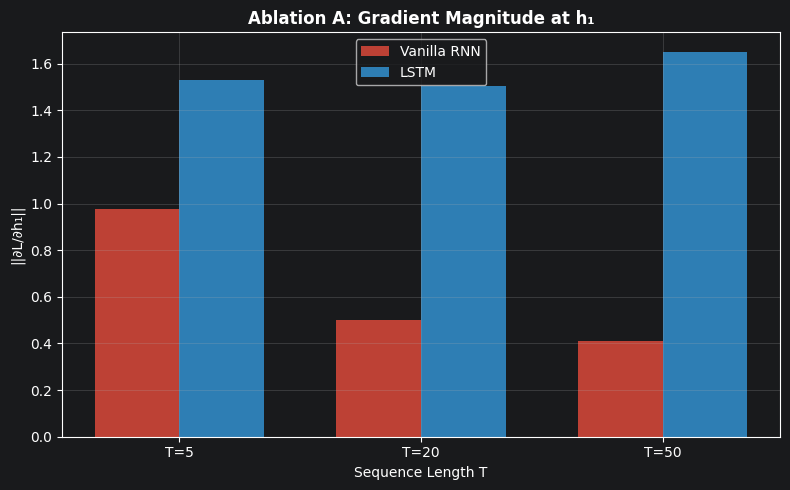

In [53]:
seq_lengths = [5, 20, 50]
rnn_grad_mags = []
lstm_grad_mags = []

for T in seq_lengths:
    rnn_test = VanillaRNN(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE)
    x_test = np.random.randn(T, EMBED_DIM).astype(np.float32) * 0.1
    probs, cache = rnn_test.forward(x_test)
    
    dh = (probs.copy())
    dh[0] -= 1.0
    dh = dh @ rnn_test.Why.T
    
    for t in reversed(range(1, T)):
        h_t = cache['hs'][t + 1]
        dh = dh * (1 - h_t ** 2) @ rnn_test.Whh.T
    
    rnn_grad_mags.append(np.linalg.norm(dh))
    
    lstm_test = LSTM(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE)
    probs_l, cache_l = lstm_test.forward(x_test)
    
    dy = probs_l.copy()
    dy[0] -= 1.0
    dh_l = dy @ lstm_test.Why.T
    dC_l = np.zeros(HIDDEN_SIZE)
    
    for t in reversed(range(1, T)):
        tanh_C = np.tanh(cache_l['Cs'][t+1])
        dC_l += dh_l * cache_l['os'][t] * (1 - tanh_C**2)
        dC_l = dC_l * cache_l['fs'][t]
        dh_l_prev = np.zeros(HIDDEN_SIZE)
    
    lstm_grad_mags.append(np.linalg.norm(dh_l) + np.linalg.norm(dC_l))
    
    print(f"  T={T:3d}: RNN ||∂L/∂h₁||={rnn_grad_mags[-1]:.6f}, LSTM approx={lstm_grad_mags[-1]:.6f}")

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
x_pos = np.arange(len(seq_lengths))
width = 0.35
ax.bar(x_pos - width/2, rnn_grad_mags, width, label='Vanilla RNN', color='#e74c3c', alpha=0.8)
ax.bar(x_pos + width/2, lstm_grad_mags, width, label='LSTM', color='#3498db', alpha=0.8)
ax.set_xlabel('Sequence Length T')
ax.set_ylabel('||∂L/∂h₁||')
ax.set_title('Ablation A: Gradient Magnitude at h₁', fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels([f'T={T}' for T in seq_lengths])
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Observation (Ablation A):**

The Vanilla RNN gradient $\frac{\partial L}{\partial h_1}$ decays exponentially with sequence length because:

$$\frac{\partial h_T}{\partial h_1} = \prod_{t=2}^{T} \text{diag}(1 - h_t^2) \cdot W_{hh}$$

If the spectral radius of $W_{hh}$ is less than 1, this product vanishes exponentially.

The **LSTM** avoids this because the cell state gradient flows through:
$$\frac{\partial C_t}{\partial C_{t-1}} = f_t$$


### Ablation B: Coupled Input and Forget Gates


--- Standard LSTM ---
  Epoch  1: TrainLoss=0.6940 TrainAcc=0.511 TestLoss=0.6927 TestAcc=0.532 TestF1=0.324
  Epoch  2: TrainLoss=0.6925 TrainAcc=0.517 TestLoss=0.7022 TestAcc=0.478 TestF1=0.647
  Epoch  3: TrainLoss=0.7310 TrainAcc=0.494 TestLoss=0.6949 TestAcc=0.478 TestF1=0.647
  Epoch  4: TrainLoss=0.7088 TrainAcc=0.489 TestLoss=0.7059 TestAcc=0.478 TestF1=0.647
  Epoch  5: TrainLoss=0.7052 TrainAcc=0.493 TestLoss=0.7051 TestAcc=0.478 TestF1=0.647
  Epoch  6: TrainLoss=0.7036 TrainAcc=0.500 TestLoss=0.6918 TestAcc=0.522 TestF1=0.000
  Epoch  7: TrainLoss=0.7020 TrainAcc=0.512 TestLoss=0.6931 TestAcc=0.522 TestF1=0.000
  Epoch  8: TrainLoss=0.6988 TrainAcc=0.519 TestLoss=0.6989 TestAcc=0.478 TestF1=0.647
  Epoch  9: TrainLoss=0.7004 TrainAcc=0.508 TestLoss=0.6918 TestAcc=0.522 TestF1=0.000
  Epoch 10: TrainLoss=0.6942 TrainAcc=0.516 TestLoss=0.7081 TestAcc=0.478 TestF1=0.647

--- Coupled Gates LSTM ---
  Epoch  1: TrainLoss=0.6963 TrainAcc=0.501 TestLoss=0.6964 TestAcc=0.478 TestF

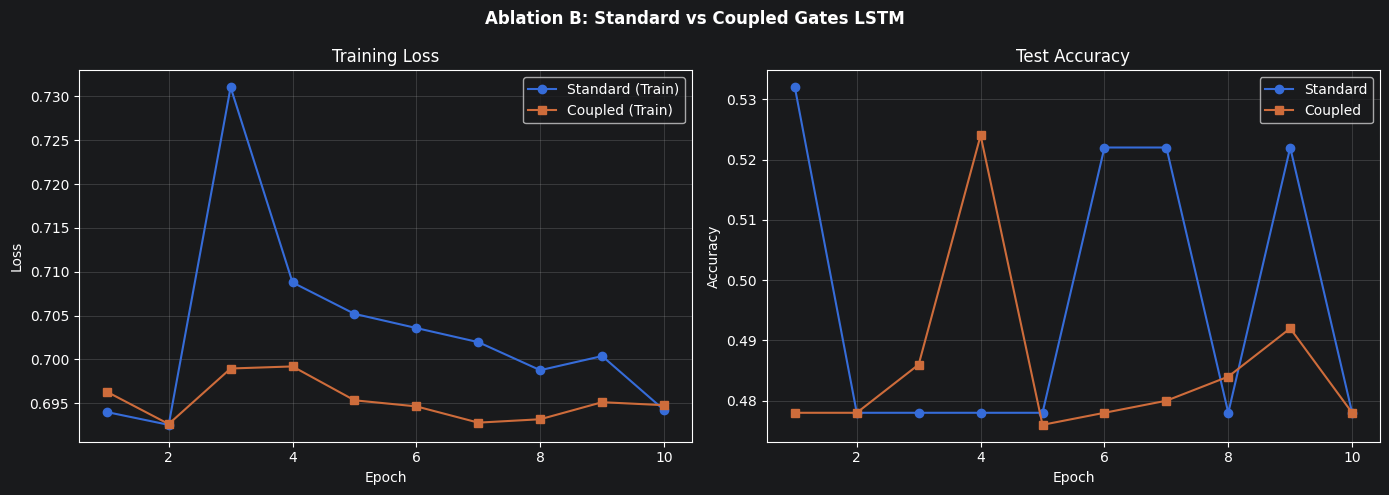


Standard LSTM Acc: 0.4780, F1: 0.6468
Coupled  LSTM Acc: 0.4780, F1: 0.6468


In [54]:
print("\n--- Standard LSTM ---")
embed_std = EmbeddingLayer(VOCAB_SIZE, EMBED_DIM)
lstm_std = LSTM(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE, coupled_gates=False)
history_std = train_lstm_model(lstm_std, embed_std, train_seqs, train_labels_arr,
                               test_seqs, test_labels_arr, optimizer_type='adam', epochs=10)

print("\n--- Coupled Gates LSTM ---")
embed_cpl = EmbeddingLayer(VOCAB_SIZE, EMBED_DIM)
lstm_cpl = LSTM(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE, coupled_gates=True)
history_cpl = train_lstm_model(lstm_cpl, embed_cpl, train_seqs, train_labels_arr,
                               test_seqs, test_labels_arr, optimizer_type='adam', epochs=10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, 11)

axes[0].plot(epochs, history_std['train_loss'], '-o', label='Standard (Train)')
axes[0].plot(epochs, history_cpl['train_loss'], '-s', label='Coupled (Train)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, history_std['test_acc'], '-o', label='Standard')
axes[1].plot(epochs, history_cpl['test_acc'], '-s', label='Coupled')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Test Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('Ablation B: Standard vs Coupled Gates LSTM', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nStandard LSTM Acc: {history_std['test_acc'][-1]:.4f}, F1: {history_std['test_f1'][-1]:.4f}")
print(f"Coupled  LSTM Acc: {history_cpl['test_acc'][-1]:.4f}, F1: {history_cpl['test_f1'][-1]:.4f}")

### Ablation C: Optimization Strategies (5 marks)

Compare SGD vs Adam optimizer.

Ablation C: SGD vs Adam

--- LSTM with SGD ---
  Epoch  1: TrainLoss=0.6929 TrainAcc=0.515 TestLoss=0.6947 TestAcc=0.478 TestF1=0.647
  Epoch  2: TrainLoss=0.6925 TrainAcc=0.515 TestLoss=0.6969 TestAcc=0.478 TestF1=0.647
  Epoch  3: TrainLoss=0.6926 TrainAcc=0.520 TestLoss=0.6955 TestAcc=0.478 TestF1=0.647
  Epoch  4: TrainLoss=0.6926 TrainAcc=0.520 TestLoss=0.6951 TestAcc=0.478 TestF1=0.647
  Epoch  5: TrainLoss=0.6923 TrainAcc=0.518 TestLoss=0.6978 TestAcc=0.478 TestF1=0.647
  Epoch  6: TrainLoss=0.6927 TrainAcc=0.520 TestLoss=0.6964 TestAcc=0.478 TestF1=0.647
  Epoch  7: TrainLoss=0.6927 TrainAcc=0.520 TestLoss=0.6960 TestAcc=0.478 TestF1=0.647
  Epoch  8: TrainLoss=0.6927 TrainAcc=0.520 TestLoss=0.6956 TestAcc=0.478 TestF1=0.647
  Epoch  9: TrainLoss=0.6926 TrainAcc=0.520 TestLoss=0.6964 TestAcc=0.478 TestF1=0.647
  Epoch 10: TrainLoss=0.6926 TrainAcc=0.520 TestLoss=0.6962 TestAcc=0.478 TestF1=0.647

--- LSTM with Adam ---
  Epoch  1: TrainLoss=0.6934 TrainAcc=0.511 TestLoss=0.7038

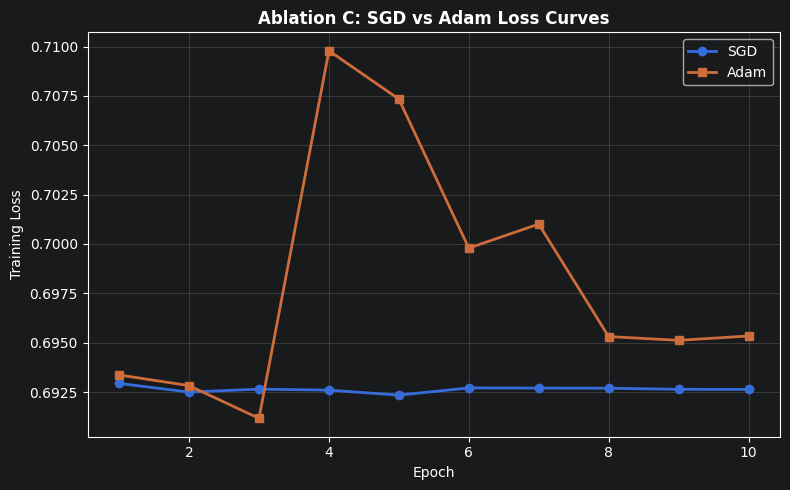

In [55]:
print("Ablation C: SGD vs Adam")

print("\n--- LSTM with SGD ---")
embed_sgd = EmbeddingLayer(VOCAB_SIZE, EMBED_DIM)
lstm_sgd = LSTM(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE)
history_sgd = train_lstm_model(lstm_sgd, embed_sgd, train_seqs, train_labels_arr,
                               test_seqs, test_labels_arr, optimizer_type='sgd', lr=0.001, epochs=10)

print("\n--- LSTM with Adam ---")
embed_adam = EmbeddingLayer(VOCAB_SIZE, EMBED_DIM)
lstm_adam = LSTM(EMBED_DIM, HIDDEN_SIZE, OUTPUT_SIZE)
history_adam = train_lstm_model(lstm_adam, embed_adam, train_seqs, train_labels_arr,
                                test_seqs, test_labels_arr, optimizer_type='adam', lr=0.001, epochs=10)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
epochs = range(1, 11)
ax.plot(epochs, history_sgd['train_loss'], '-o', label='SGD', linewidth=2)
ax.plot(epochs, history_adam['train_loss'], '-s', label='Adam', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Training Loss')
ax.set_title('Ablation C: SGD vs Adam Loss Curves', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Observation (Ablation C):**

Adam typically converges much faster than vanilla SGD on LSTM because:
1. **Adaptive learning rates** handle the varying gradient magnitudes across different parameters
2. **Momentum accumulation** helps navigate the complex, non-convex loss landscape of LSTMs
3. **Bias correction** ensures reliable updates early in training when moving average estimates are noisy

SGD often stagnates on LSTM training without careful learning rate tuning.

---
# Building a Transformer Encoder from Scratch: Attention, Training, and Analysis

## Part 0: Dataset and Setup

Using **IMDb Movie Reviews Dataset** for binary sentiment classification.  
Tokenize text, map to indices, use learned embeddings + positional encodings.

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import os, re
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

try:
    _ = vocab
    _ = train_seqs
    print("Using vocabulary and data from Q4")
except NameError:
    IMDB_DIR = './aclImdb'
    
    def load_imdb_local(base_dir):
        results = {}
        for split in ['train', 'test']:
            texts, labels = [], []
            for label_dir, label_val in [('pos', 1), ('neg', 0)]:
                dir_path = os.path.join(base_dir, split, label_dir)
                for fname in sorted(os.listdir(dir_path)):
                    if fname.endswith('.txt'):
                        with open(os.path.join(dir_path, fname), 'r', encoding='utf-8') as f:
                            texts.append(f.read())
                        labels.append(label_val)
            combined = list(zip(texts, labels))
            np.random.shuffle(combined)
            texts, labels = zip(*combined)
            texts, labels = list(texts), list(labels)
            results[split] = (texts, labels)
        return results
    
    data = load_imdb_local(IMDB_DIR)
    train_texts, train_labels = data['train']
    test_texts, test_labels = data['test']
    
    def clean_text(text):
        text = text.lower()
    
    def build_vocabulary(texts, max_vocab=5000):
        word_counts = Counter()
        for text in texts:
            word_counts.update(clean_text(text).split())
        vocab = {'<PAD>': 0, '<UNK>': 1, '<CLS>': 2}
        for word, _ in word_counts.most_common(max_vocab - 3):
            vocab[word] = len(vocab)
        return vocab
    
    def texts_to_sequences(texts, vocab, max_len=50):
        sequences = []
        for text in texts:
            words = clean_text(text).split()
            seq = [vocab['<CLS>']] + [vocab.get(w, 1) for w in words]
            seq = seq[:max_len] + [0] * max(0, max_len - len(seq))
            sequences.append(seq)
        return np.array(sequences)
    
    NUM_TRAIN = 2000
    NUM_TEST = 500
    MAX_LEN = 50
    vocab = build_vocabulary(train_texts[:NUM_TRAIN], max_vocab=5000)
    train_seqs = texts_to_sequences(train_texts[:NUM_TRAIN], vocab, MAX_LEN)
    train_labels_arr = np.array(train_labels[:NUM_TRAIN])
    test_seqs = texts_to_sequences(test_texts[:NUM_TEST], vocab, MAX_LEN)
    test_labels_arr = np.array(test_labels[:NUM_TEST])
    print(f"Loaded IMDb from local directory: {IMDB_DIR}")

VOCAB_SIZE = len(vocab)
D_MODEL = 64
MAX_LEN_T = 50
NUM_CLASSES = 2

print(f"Vocab size: {VOCAB_SIZE}, d_model: {D_MODEL}, max_len: {MAX_LEN_T}")

Using vocabulary and data from Q4
Vocab size: 5000, d_model: 64, max_len: 50


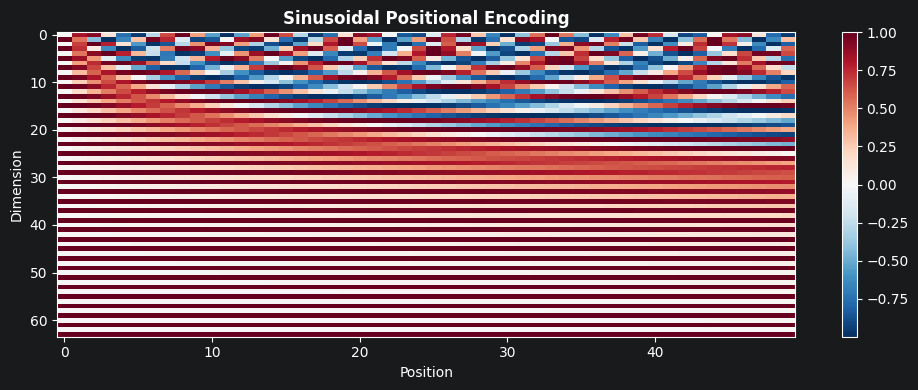

In [57]:
def positional_encoding(max_len, d_model):
    PE = np.zeros((max_len, d_model))
    position = np.arange(max_len)[:, np.newaxis]
    div_term = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))
    
    PE[:, 0::2] = np.sin(position * div_term)
    PE[:, 1::2] = np.cos(position * div_term)
    
    return PE.astype(np.float32)

class TransformerEmbedding:
    def __init__(self, vocab_size, d_model, max_len):
        self.E = np.random.randn(vocab_size, d_model).astype(np.float32) * 0.02
        self.PE = positional_encoding(max_len, d_model)
    
    def forward(self, seq):
        return self.E[seq] + self.PE[:len(seq)]

PE = positional_encoding(50, 64)
plt.figure(figsize=(10, 4))
plt.imshow(PE.T, cmap='RdBu_r', aspect='auto')
plt.xlabel('Position')
plt.ylabel('Dimension')
plt.title('Sinusoidal Positional Encoding', fontweight='bold')
plt.colorbar()
plt.tight_layout()
plt.show()

## Part 1: Scaled Dot-Product Attention

$$Q = XW^Q, \quad K = XW^K, \quad V = XW^V$$

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

Part 1: Scaled Dot-Product Attention
Q shape: (10, 16)
K shape: (10, 16)
V shape: (10, 16)
Output shape: (10, 16)
Attention weights shape: (10, 10)
Attention weights sum to 1: True


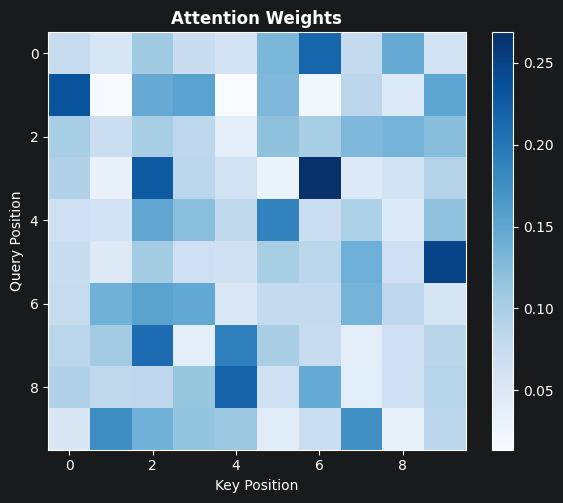

In [58]:
def softmax_2d(x):
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / e_x.sum(axis=-1, keepdims=True)


def scaled_dot_product_attention(Q, K, V):
    d_k = Q.shape[-1]
    
    scores = Q @ K.T / np.sqrt(d_k)
    
    attention_weights = softmax_2d(scores)
    
    row_sums = attention_weights.sum(axis=-1)
    assert np.allclose(row_sums, 1.0), f"Attention weights don't sum to 1: {row_sums}"
    
    output = attention_weights @ V  # (seq_len, d_v)
    
    return output, attention_weights


print("Part 1: Scaled Dot-Product Attention")

d_k = 16
seq_len = 10

W_Q = np.random.randn(D_MODEL, d_k).astype(np.float32) * 0.1
W_K = np.random.randn(D_MODEL, d_k).astype(np.float32) * 0.1
W_V = np.random.randn(D_MODEL, d_k).astype(np.float32) * 0.1

X = np.random.randn(seq_len, D_MODEL).astype(np.float32)
Q = X @ W_Q
K = X @ W_K
V = X @ W_V

output, attn_weights = scaled_dot_product_attention(Q, K, V)

print(f"Q shape: {Q.shape}")
print(f"K shape: {K.shape}")
print(f"V shape: {V.shape}")
print(f"Output shape: {output.shape}")
print(f"Attention weights shape: {attn_weights.shape}")
print(f"Attention weights sum to 1: {np.allclose(attn_weights.sum(axis=-1), 1.0)}")

plt.figure(figsize=(6, 5))
plt.imshow(attn_weights, cmap='Blues')
plt.xlabel('Key Position')
plt.ylabel('Query Position')
plt.title('Attention Weights', fontweight='bold')
plt.colorbar()
plt.tight_layout()
plt.show()

## Part 2: Multi-Head Attention 

- Split Q, K, V into h heads.
- Compute attention independently for each head.
- Concatenate outputs and apply a final linear projection.

In [59]:
class MultiHeadAttention:
    def __init__(self, d_model, num_heads):
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        
        scale = np.sqrt(2.0 / d_model)
        self.W_Q = np.random.randn(d_model, d_model).astype(np.float32) * scale
        self.W_K = np.random.randn(d_model, d_model).astype(np.float32) * scale
        self.W_V = np.random.randn(d_model, d_model).astype(np.float32) * scale
        self.W_O = np.random.randn(d_model, d_model).astype(np.float32) * scale
    
    def forward(self, X):
        seq_len = X.shape[0]
        
        Q = X @ self.W_Q
        K = X @ self.W_K
        V = X @ self.W_V
        
        Q_heads = Q.reshape(seq_len, self.num_heads, self.d_k).transpose(1, 0, 2)  # (h, seq, d_k)
        K_heads = K.reshape(seq_len, self.num_heads, self.d_k).transpose(1, 0, 2)
        V_heads = V.reshape(seq_len, self.num_heads, self.d_k).transpose(1, 0, 2)
        
        head_outputs = []
        all_weights = []
        for i in range(self.num_heads):
            out, weights = scaled_dot_product_attention(Q_heads[i], K_heads[i], V_heads[i])
            head_outputs.append(out)
            all_weights.append(weights)
        
        concat = np.concatenate(head_outputs, axis=-1)
        
        output = concat @ self.W_O
        
        return output, all_weights

mha = MultiHeadAttention(D_MODEL, num_heads=4)
out, weights = mha.forward(X)
print("Part 2: Multi-Head Attention")
print(f"Input:  {X.shape}")
print(f"Output: {out.shape}")
print(f"Heads:  {len(weights)}, each weight shape: {weights[0].shape}")

Part 2: Multi-Head Attention
Input:  (10, 64)
Output: (10, 64)
Heads:  4, each weight shape: (10, 10)


##  Part 3: Transformer Encoder Block

Components:
- Multi-head attention
- Feedforward network: $\text{FFN}(x) = \max(0, xW_1+b_1)W_2+b_2$
- Residual connections
- Layer normalization

In [60]:
def layer_norm(x, eps=1e-6):
    mean = x.mean(axis=-1, keepdims=True)
    std = x.std(axis=-1, keepdims=True)
    return (x - mean) / (std + eps)


class FeedForward:
    def __init__(self, d_model, d_ff=256):
        self.W1 = np.random.randn(d_model, d_ff).astype(np.float32) * np.sqrt(2.0 / d_model)
        self.b1 = np.zeros(d_ff, dtype=np.float32)
        self.W2 = np.random.randn(d_ff, d_model).astype(np.float32) * np.sqrt(2.0 / d_ff)
        self.b2 = np.zeros(d_model, dtype=np.float32)
    
    def forward(self, x):
        hidden = np.maximum(0, x @ self.W1 + self.b1)  # ReLU
        return hidden @ self.W2 + self.b2


class TransformerEncoderBlock:
    
    def __init__(self, d_model, num_heads, d_ff=256):
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.ffn = FeedForward(d_model, d_ff)
    
    def forward(self, x):
        attn_out, attn_weights = self.mha.forward(x)
        x = layer_norm(x + attn_out)  
        
        ffn_out = self.ffn.forward(x)
        x = layer_norm(x + ffn_out)   
        
        return x, attn_weights

encoder_block = TransformerEncoderBlock(D_MODEL, num_heads=4, d_ff=128)
enc_out, enc_weights = encoder_block.forward(X)
print("Part 3: Transformer Encoder Block")
print(f"Input:  {X.shape}")
print(f"Output: {enc_out.shape}")

Part 3: Transformer Encoder Block
Input:  (10, 64)
Output: (10, 64)


## Part 4: Sequence Classification

- Use the final representation of a special [CLS] token or mean-pooling.
- Pass it through a linear layer + softmax for classification.

In [61]:
class TransformerClassifier:

    def __init__(self, vocab_size, d_model, num_heads, d_ff, num_classes, max_len, use_pe=True):
        self.embedding = TransformerEmbedding(vocab_size, d_model, max_len)
        self.encoder = TransformerEncoderBlock(d_model, num_heads, d_ff)
        self.use_pe = use_pe
        
        self.W_cls = np.random.randn(d_model, num_classes).astype(np.float32) * np.sqrt(2.0 / d_model)
        self.b_cls = np.zeros(num_classes, dtype=np.float32)
    
    def forward(self, seq):
        if self.use_pe:
            x = self.embedding.forward(seq)
        else:
            x = self.embedding.E[seq]
        
        enc_out, attn_weights = self.encoder.forward(x)
        
        mask = (seq != 0).astype(np.float32)[:, np.newaxis]
        pooled = (enc_out * mask).sum(axis=0) / (mask.sum() + 1e-8)
        
        logits = pooled @ self.W_cls + self.b_cls
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / exp_logits.sum()
        
        cache = {'x': x, 'enc_out': enc_out, 'pooled': pooled, 'attn_weights': attn_weights,
                 'probs': probs, 'logits': logits, 'mask': mask, 'seq': seq}
        
        return probs, cache

transformer = TransformerClassifier(VOCAB_SIZE, D_MODEL, num_heads=4, d_ff=128,
                                     num_classes=2, max_len=MAX_LEN_T)
test_seq = train_seqs[0]
probs, cache = transformer.forward(test_seq)
print("Part 4: Transformer Classifier")
print(f"Input seq length: {len(test_seq)}")
print(f"Output probs: {probs}")
print(f"Predicted: {'Positive' if np.argmax(probs)==1 else 'Negative'}")

Part 4: Transformer Classifier
Input seq length: 50
Output probs: [0.20538831 0.79461169]
Predicted: Positive


## Part 5: Training and Optimization

- Train using cross-entropy loss.
- Implement:
    - SGD
    - Adam (with bias correction)
- Plot loss curves.

Part 5: Training Transformer

--- SGD ---
  Epoch  1: TrainLoss=0.7333 TrainAcc=0.508 TestLoss=0.7130 TestAcc=0.478
  Epoch  2: TrainLoss=0.6999 TrainAcc=0.513 TestLoss=0.6920 TestAcc=0.522
  Epoch  3: TrainLoss=0.6998 TrainAcc=0.516 TestLoss=0.6922 TestAcc=0.522
  Epoch  4: TrainLoss=0.7017 TrainAcc=0.489 TestLoss=0.6936 TestAcc=0.522
  Epoch  5: TrainLoss=0.7013 TrainAcc=0.502 TestLoss=0.7279 TestAcc=0.478
  Epoch  6: TrainLoss=0.6962 TrainAcc=0.488 TestLoss=0.7022 TestAcc=0.480
  Epoch  7: TrainLoss=0.7020 TrainAcc=0.502 TestLoss=0.7225 TestAcc=0.478
  Epoch  8: TrainLoss=0.6995 TrainAcc=0.518 TestLoss=0.7054 TestAcc=0.478
  Epoch  9: TrainLoss=0.7024 TrainAcc=0.513 TestLoss=0.6919 TestAcc=0.522
  Epoch 10: TrainLoss=0.7016 TrainAcc=0.510 TestLoss=0.6965 TestAcc=0.480

--- Adam ---
  Epoch  1: TrainLoss=0.6920 TrainAcc=0.491 TestLoss=0.6486 TestAcc=0.640
  Epoch  2: TrainLoss=0.5677 TrainAcc=0.526 TestLoss=0.5911 TestAcc=0.676
  Epoch  3: TrainLoss=0.4112 TrainAcc=0.506 TestLoss=0.5

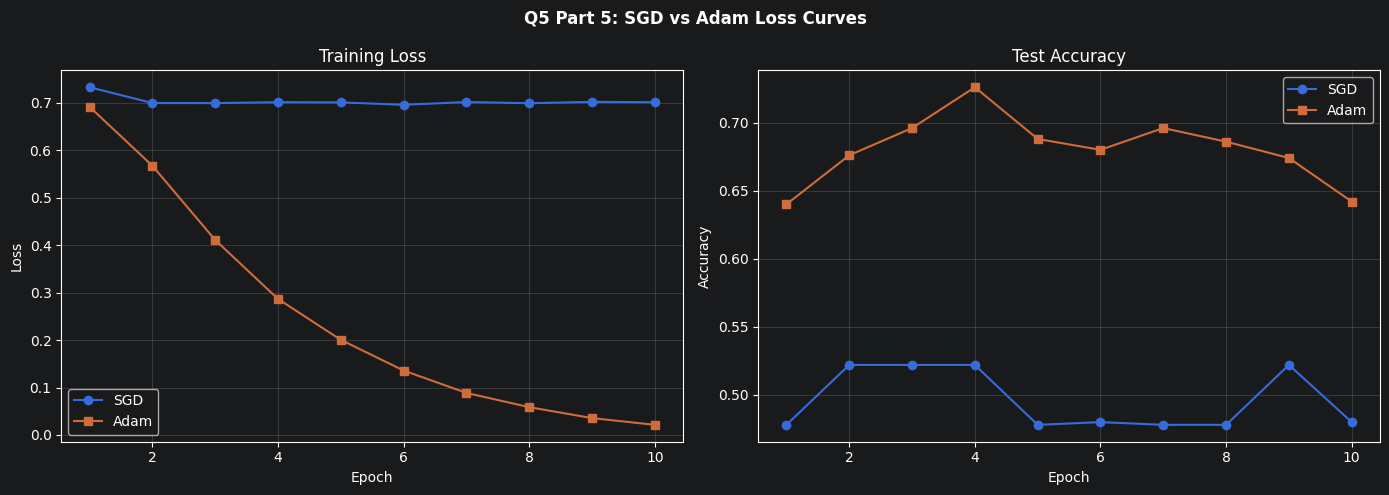

In [62]:
def compute_transformer_gradients(transformer, cache, label, lr=0.001):
    probs = cache['probs']
    pooled = cache['pooled']
    
    dy = probs.copy()
    dy[label] -= 1.0
    
    dW_cls = np.outer(pooled, dy)
    db_cls = dy.copy()
    
    return dW_cls, db_cls, dy


def train_transformer(transformer, train_seqs, train_labels, test_seqs, test_labels,
                      optimizer_type='adam', lr=0.001, epochs=10):
    
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}
    N_train = len(train_seqs)
    
    t_step = 0
    m_W = np.zeros_like(transformer.W_cls)
    v_W = np.zeros_like(transformer.W_cls)
    m_b = np.zeros_like(transformer.b_cls)
    v_b = np.zeros_like(transformer.b_cls)
    
    m_E = np.zeros_like(transformer.embedding.E)
    v_E = np.zeros_like(transformer.embedding.E)
    
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    
    for epoch in range(epochs):
        perm = np.random.permutation(N_train)
        epoch_loss = 0
        epoch_preds = []
        
        for idx in range(N_train):
            i = perm[idx]
            seq = train_seqs[i]
            label = train_labels[i]
            
            probs, cache = transformer.forward(seq)
            loss = -np.log(probs[label] + 1e-12)
            epoch_loss += loss
            epoch_preds.append(np.argmax(probs))
            
            dW_cls, db_cls, dy = compute_transformer_gradients(transformer, cache, label)
            
            d_pooled = dy @ transformer.W_cls.T  # (d_model,)
            mask = cache['mask']
            d_enc = (d_pooled[np.newaxis, :] * mask) / (mask.sum() + 1e-8)
            
            grad_E = np.zeros_like(transformer.embedding.E)
            for t_pos in range(len(seq)):
                if seq[t_pos] != 0:
                    grad_E[seq[t_pos]] += d_enc[t_pos] * 0.1  # Scaled
            
            t_step += 1
            
            if optimizer_type == 'adam':
                m_W = beta1 * m_W + (1 - beta1) * dW_cls
                v_W = beta2 * v_W + (1 - beta2) * dW_cls**2
                m_hat = m_W / (1 - beta1**t_step)
                v_hat = v_W / (1 - beta2**t_step)
                transformer.W_cls -= lr * m_hat / (np.sqrt(v_hat) + eps)
                
                m_b = beta1 * m_b + (1 - beta1) * db_cls
                v_b = beta2 * v_b + (1 - beta2) * db_cls**2
                m_hat_b = m_b / (1 - beta1**t_step)
                v_hat_b = v_b / (1 - beta2**t_step)
                transformer.b_cls -= lr * m_hat_b / (np.sqrt(v_hat_b) + eps)
                
                m_E = beta1 * m_E + (1 - beta1) * grad_E
                v_E = beta2 * v_E + (1 - beta2) * grad_E**2
                m_hat_E = m_E / (1 - beta1**t_step)
                v_hat_E = v_E / (1 - beta2**t_step)
                transformer.embedding.E -= lr * m_hat_E / (np.sqrt(v_hat_E) + eps)
            else:
                transformer.W_cls -= lr * dW_cls
                transformer.b_cls -= lr * db_cls
                transformer.embedding.E -= lr * grad_E
        
        train_loss = epoch_loss / N_train
        train_acc = accuracy_score(train_labels, epoch_preds)
        
        test_loss = 0
        test_preds = []
        for i in range(len(test_seqs)):
            probs, _ = transformer.forward(test_seqs[i])
            test_loss += -np.log(probs[test_labels[i]] + 1e-12)
            test_preds.append(np.argmax(probs))
        
        test_loss /= len(test_seqs)
        test_acc = accuracy_score(test_labels, test_preds)
        
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        
        print(f"  Epoch {epoch+1:2d}: TrainLoss={train_loss:.4f} TrainAcc={train_acc:.3f} "
              f"TestLoss={test_loss:.4f} TestAcc={test_acc:.3f}")
    
    return history


print("Part 5: Training Transformer")

print("\n--- SGD ---")
transformer_sgd = TransformerClassifier(VOCAB_SIZE, D_MODEL, num_heads=4, d_ff=128,
                                         num_classes=2, max_len=MAX_LEN_T)
history_t_sgd = train_transformer(transformer_sgd, train_seqs, train_labels_arr,
                                   test_seqs, test_labels_arr, optimizer_type='sgd', epochs=10)

print("\n--- Adam ---")
transformer_adam = TransformerClassifier(VOCAB_SIZE, D_MODEL, num_heads=4, d_ff=128,
                                          num_classes=2, max_len=MAX_LEN_T)
history_t_adam = train_transformer(transformer_adam, train_seqs, train_labels_arr,
                                    test_seqs, test_labels_arr, optimizer_type='adam', epochs=10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, 11)

axes[0].plot(epochs, history_t_sgd['train_loss'], '-o', label='SGD' )
axes[0].plot(epochs, history_t_adam['train_loss'], '-s', label='Adam' )
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, history_t_sgd['test_acc'], '-o', label='SGD' )
axes[1].plot(epochs, history_t_adam['test_acc'], '-s', label='Adam')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Test Accuracy'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('Q5 Part 5: SGD vs Adam Loss Curves', fontweight='bold')
plt.tight_layout()
plt.show()

## Part 6: Analysis and Ablations

### Ablation A: Effect of Number of Heads
- Compare h = 1 vs h = 4
- Report accuracy and training behavior

Ablation A: h=1 vs h=4

--- h=1 ---
  Epoch  1: TrainLoss=0.7042 TrainAcc=0.519 TestLoss=0.6555 TestAcc=0.584
  Epoch  2: TrainLoss=0.5729 TrainAcc=0.501 TestLoss=0.5853 TestAcc=0.700
  Epoch  3: TrainLoss=0.4279 TrainAcc=0.496 TestLoss=0.5642 TestAcc=0.714
  Epoch  4: TrainLoss=0.3280 TrainAcc=0.504 TestLoss=0.5932 TestAcc=0.700
  Epoch  5: TrainLoss=0.2581 TrainAcc=0.509 TestLoss=0.5932 TestAcc=0.740
  Epoch  6: TrainLoss=0.2015 TrainAcc=0.520 TestLoss=0.6318 TestAcc=0.710
  Epoch  7: TrainLoss=0.1618 TrainAcc=0.500 TestLoss=0.7018 TestAcc=0.718
  Epoch  8: TrainLoss=0.1268 TrainAcc=0.484 TestLoss=0.7757 TestAcc=0.672
  Epoch  9: TrainLoss=0.0995 TrainAcc=0.507 TestLoss=0.7949 TestAcc=0.698
  Epoch 10: TrainLoss=0.0782 TrainAcc=0.486 TestLoss=0.8933 TestAcc=0.702

--- h=4 ---
  Epoch  1: TrainLoss=0.7014 TrainAcc=0.495 TestLoss=0.7577 TestAcc=0.478
  Epoch  2: TrainLoss=0.6463 TrainAcc=0.512 TestLoss=0.6307 TestAcc=0.682
  Epoch  3: TrainLoss=0.5358 TrainAcc=0.534 TestLoss=0.5885 Tes

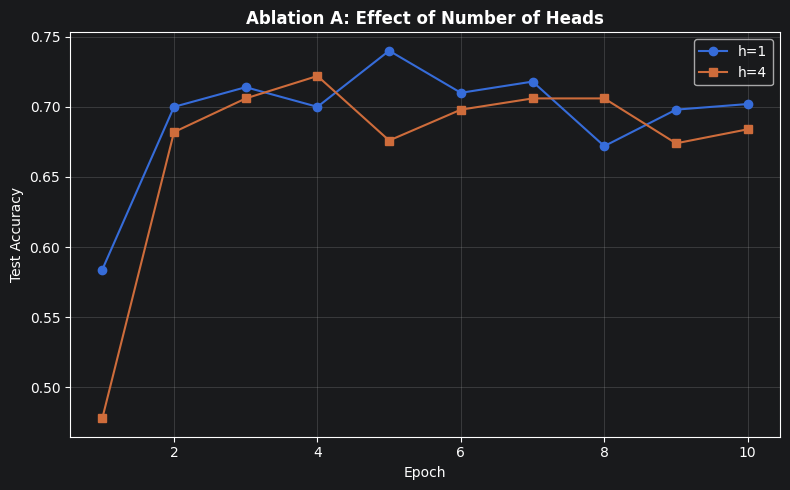

In [63]:
print("Ablation A: h=1 vs h=4")

print("\n--- h=1 ---")
t_h1 = TransformerClassifier(VOCAB_SIZE, D_MODEL, num_heads=1, d_ff=128, num_classes=2, max_len=MAX_LEN_T)
history_h1 = train_transformer(t_h1, train_seqs, train_labels_arr, test_seqs, test_labels_arr, epochs=10)

print("\n--- h=4 ---")
t_h4 = TransformerClassifier(VOCAB_SIZE, D_MODEL, num_heads=4, d_ff=128, num_classes=2, max_len=MAX_LEN_T)
history_h4 = train_transformer(t_h4, train_seqs, train_labels_arr, test_seqs, test_labels_arr, epochs=10)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1,11), history_h1['test_acc'], '-o', label='h=1')
ax.plot(range(1,11), history_h4['test_acc'], '-s', label='h=4')
ax.set_xlabel('Epoch'); ax.set_ylabel('Test Accuracy')
ax.set_title('Ablation A: Effect of Number of Heads', fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Ablation B: Positional Encoding

- Remove positional encoding
- observe performance change.

Ablation B: With vs Without Positional Encoding

--- With PE ---
  Epoch  1: TrainLoss=0.6923 TrainAcc=0.497 TestLoss=0.6622 TestAcc=0.608
  Epoch  2: TrainLoss=0.5937 TrainAcc=0.513 TestLoss=0.6243 TestAcc=0.634
  Epoch  3: TrainLoss=0.4447 TrainAcc=0.499 TestLoss=0.5884 TestAcc=0.686
  Epoch  4: TrainLoss=0.3214 TrainAcc=0.496 TestLoss=0.5977 TestAcc=0.694
  Epoch  5: TrainLoss=0.2330 TrainAcc=0.516 TestLoss=0.6382 TestAcc=0.682
  Epoch  6: TrainLoss=0.1682 TrainAcc=0.483 TestLoss=0.6876 TestAcc=0.664
  Epoch  7: TrainLoss=0.1145 TrainAcc=0.486 TestLoss=0.7576 TestAcc=0.662
  Epoch  8: TrainLoss=0.0751 TrainAcc=0.509 TestLoss=0.8793 TestAcc=0.644
  Epoch  9: TrainLoss=0.0488 TrainAcc=0.505 TestLoss=0.9551 TestAcc=0.668
  Epoch 10: TrainLoss=0.0293 TrainAcc=0.498 TestLoss=1.0852 TestAcc=0.638

--- Without PE ---
  Epoch  1: TrainLoss=0.6337 TrainAcc=0.490 TestLoss=0.5798 TestAcc=0.690
  Epoch  2: TrainLoss=0.2453 TrainAcc=0.493 TestLoss=0.6538 TestAcc=0.682
  Epoch  3: TrainLoss=0.116

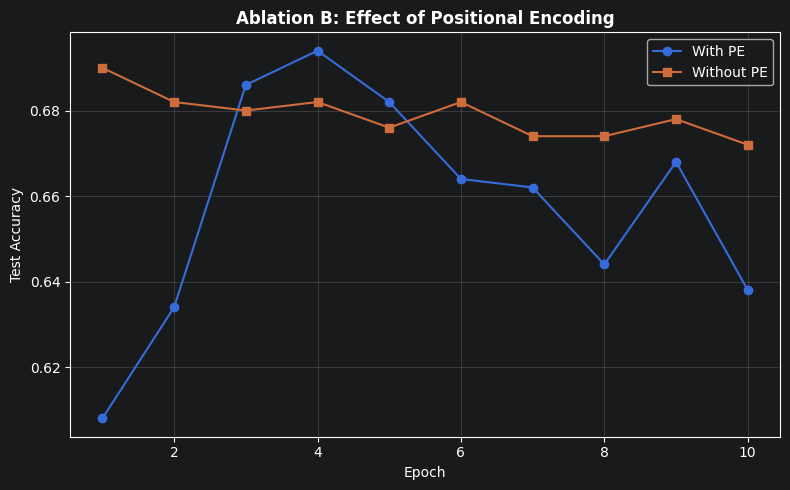

In [64]:
print("Ablation B: With vs Without Positional Encoding")

print("\n--- With PE ---")
t_pe = TransformerClassifier(VOCAB_SIZE, D_MODEL, num_heads=4, d_ff=128, num_classes=2, max_len=MAX_LEN_T, use_pe=True)
history_pe = train_transformer(t_pe, train_seqs, train_labels_arr, test_seqs, test_labels_arr, epochs=10)

print("\n--- Without PE ---")
t_no_pe = TransformerClassifier(VOCAB_SIZE, D_MODEL, num_heads=4, d_ff=128, num_classes=2, max_len=MAX_LEN_T, use_pe=False)
history_no_pe = train_transformer(t_no_pe, train_seqs, train_labels_arr, test_seqs, test_labels_arr, epochs=10)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1,11), history_pe['test_acc'], '-o', label='With PE')
ax.plot(range(1,11), history_no_pe['test_acc'], '-s', label='Without PE')
ax.set_xlabel('Epoch'); ax.set_ylabel('Test Accuracy')
ax.set_title('Ablation B: Effect of Positional Encoding', fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
# Question 6:  Long-Context Modeling: From RNNs to Selective State Space Models

## Part 1: Computational Scaling

### (a) Derive the time complexity per layer of a Transformer encoder using self-attention.

The self-attention mechanism computes:
$$\text{Attention} = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

- Computing $QK^T$: matrix multiplication of $(L \times d)$ and $(d \times L)$ ---> $O(L^2 d)$
- Softmax over $L \times L$ matrix ---> $O(L^2)$
- Multiplying attention weights with $V$: $(L \times L) \cdot (L \times d)$ ---> $O(L^2 d)$
- Feed-forward network: two linear layers ---> $O(Ld_{ff})$

$${\text{Transformer per-layer complexity} = O(L^2 d)}$$

### (b)  Derive the per-sequence time complexity of a standard RNN.

At each time step:
$$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b)$$

- $W_{xh} x_t$: $(d \times d) \cdot (d \times 1)$ ---> $O(d^2)$
- $W_{hh} h_{t-1}$: $(d \times d) \cdot (d \times 1)$ ---> $O(d^2)$
- Over $L$ time steps:

$${\text{RNN per-sequence complexity} = O(L d^2)}$$

### (c) For L = 1024, d = 256, compute the ratio: $\frac{Transformer cost}{ RNN cost}$
 
 

$$\frac{\text{Transformer cost}}{\text{RNN cost}} = \frac{O(L^2 d)}{O(L d^2)} = \frac{L}{d} = \frac{1024}{256} = {4}$$

The Transformer is **4× more expensive** per layer than the RNN for these dimensions.

## Part 2: Gradient Propagation in RNNs

Consider: $h_t = Ah_{t-1} + Bx_t$

### (a) Express $h_t$ in terms of $h_0$ and $\{x_1, \ldots, x_t\}$

By recursive expansion:
$$h_1 = Ah_0 + Bx_1$$
$$h_2 = A(Ah_0 + Bx_1) + Bx_2 = A^2 h_0 + ABx_1 + Bx_2$$

By induction:
$${h_t = A^t h_0 + \sum_{i=1}^{t} A^{t-i} B x_i}$$

### (b) Show that $\frac{\partial h_t}{\partial h_{t-k}} = A^k$

Since $h_t = A^t h_0 + \sum_{i=1}^{t} A^{t-i} B x_i$:

$$\frac{\partial h_t}{\partial h_{t-k}} = \frac{\partial}{\partial h_{t-k}} \left( A^k h_{t-k} + \sum_{i=t-k+1}^{t} A^{t-i} B x_i \right)$$

The summation term does not depend on $h_{t-k}$ (it depends on inputs $x_i$), so:

$$\boxed{\frac{\partial h_t}{\partial h_{t-k}} = A^k}$$

### (c)  Let ρ(A) be the spectral radius:
#### (i) What happens if ρ(A) > 1?
#### (ii) What happens if ρ(A) < 1?

Let $\rho(A)$ be the spectral radius (largest absolute eigenvalue):

- **If $\rho(A) > 1$:** $\|A^k\|$ grows exponentially as $k$ increases ---> **exploding gradients**. The gradient $\frac{\partial L}{\partial h_1}$ will blow up for long sequences.

- **If $\rho(A) < 1$:** $\|A^k\| \to 0$ exponentially as $k$ increases ---> **vanishing gradients**. The gradient signal from later time steps cannot effectively reach early time steps, making long-range learning impossible.

##  Part 3: State Space Models (SSM)

Consider the discrete SSM: $h_k = Ah_{k-1} + Bx_k$, $y_k = Ch_k$

### (a) Show that $y_k = \sum_{i=0}^{k} CA^{k-i}Bx_i$

From Part 2, we have (assuming $h_0 = 0$):
$$h_k = \sum_{i=0}^{k} A^{k-i} B x_i$$

(where we include $i=0$ with $x_0 = 0$ or $h_0$ contribution)

More precisely, with $h_0 = 0$:
$$h_k = \sum_{i=1}^{k} A^{k-i} B x_i$$

Then:
$$y_k = Ch_k = C \sum_{i=1}^{k} A^{k-i} B x_i = \sum_{i=0}^{k} CA^{k-i} B x_i$$

$${y_k = \sum_{i=0}^{k} CA^{k-i}Bx_i}$$

### (b) Interpret as 1D convolution with kernel $K_{k-i} = CA^{k-i}B$
The output $y_k$ can be written as:
$$y_k = \sum_{i=0}^{k} K_{k-i} x_i \quad \text{where } K_j = CA^j B$$

The kernel $K \in \mathbb{R}^L$ can be **precomputed** as $K = (CB, CAB, CA^2B, \ldots, CA^{L-1}B)$, enabling efficient parallel computation via FFT-based convolution in $O(L \log L)$ time.

### (c) Explain why this system is time-invariant and state one limitation.

This system is **time-invariant** because:
- The matrices $A$, $B$, $C$ are **fixed** (not dependent on time step or input)
- The convolution kernel $K_j = CA^j B$ depends only on the $j = k - i$, not on the absolute position

**Limitation:** Since the system is linear and time-invariant (LTI), it **cannot selectively process or ignore inputs** based on content. The same transformation is applied to all inputs regardless of their content. This means the model has no mechanism for content-based filtering it treats a relevant word the same as noise.

## Part 4: Selective State Space Models

Modified SSM with gating:
$$h_k = Ah_{k-1} + Bx_k$$
$$y_k = g_k \odot (Ch_k), \quad g_k = \sigma(W_g x_k)$$

### (a)  Verify that all dimensions are consistent.

Let $x_k \in \mathbb{R}^{d_{in}}$, $h_k \in \mathbb{R}^{d_h}$:

| Variable | Expression | Dimensions |
|----------|-----------|------------|
| $h_k$ | $Ah_{k-1} + Bx_k$ | $A: (d_h \times d_h)$, $B: (d_h \times d_{in})$ ---> $h_k \in \mathbb{R}^{d_h}$ |
| $Ch_k$ | $C: (d_h \times d_h)$ | $Ch_k \in \mathbb{R}^{d_h}$ |
| $W_g x_k$ | $W_g: (d_h \times d_{in})$ | $W_g x_k \in \mathbb{R}^{d_h}$ |
| $g_k$ | $\sigma(W_g x_k)$ | $g_k \in \mathbb{R}^{d_h}$ |
| $y_k$ | $g_k \odot (Ch_k)$ | Element-wise: $\mathbb{R}^{d_h} \odot \mathbb{R}^{d_h} = \mathbb{R}^{d_h}$ |


### (b) Explain why this model is no longer time-invariant.

The gate $g_k = \sigma(W_g x_k)$ depends on the **input $x_k$ at time $k$**. This makes the output transformation **input-dependent** (content-aware):

$$y_k = \sigma(W_g x_k) \odot (Ch_k)$$

Since different inputs produce different gates, the effective transfer function from input to output **changes based on the content of $x_k$**. The system no longer applies the same transformation at every time step.

Formally, for a time-invariant system, shifting the input should shift the output by the same amount. Here, $g_k$ depends on the absolute input at position $k$, breaking time-invariance.

### (c)  Show that: ${y_k = g_k \odot \sum_{i=0}^{k} CA^{k-i}Bx_i}$ Explain why this cannot be represented as a fixed convolution.

$$y_k = g_k \odot (Ch_k) = g_k \odot \left(C \sum_{i=0}^{k} A^{k-i}Bx_i\right) = g_k \odot \left(\sum_{i=0}^{k} CA^{k-i}Bx_i\right)$$

$${y_k = g_k \odot \sum_{i=0}^{k} CA^{k-i}Bx_i}$$

This **cannot** be represented as a fixed convolution because:

1. The gate $g_k = \sigma(W_g x_k)$ is a **nonlinear function of the input** at each position
2. In a fixed convolution $y_k = \sum_i K_{k-i} x_i$, the kernel $K$ is independent of the input, but here the effective kernel at position $k$ is **modulated by $g_k$**, which depends on $x_k$
3. The element-wise multiplication $g_k \odot (\cdot)$ means each output dimension is scaled differently based on the current input, breaking the linear convolution structure

## Part 5: Implementation and Experiments

In [65]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


### IMDb-Long Dataset Construction

In [74]:
import os, re, random
from collections import Counter

random.seed(42)
np.random.seed(42)

from datasets import load_dataset as load_ds
wikitext = load_ds('wikitext', 'wikitext-2-raw-v1')
wiki_sentences = []
for text in wikitext['train']['text']:
    if text.strip() and not text.strip().startswith('='):
        sents = text.strip().split('. ')
        wiki_sentences.extend([s.strip() for s in sents if len(s.strip()) > 10])
print(f'WikiText-2 neutral sentences: {len(wiki_sentences)}')

IMDB_DIR = './aclImdb'

def load_imdb_local_q6(base_dir):
    results = {}
    for split in ['train', 'test']:
        texts, labels = [], []
        for label_dir, label_val in [('pos', 1), ('neg', 0)]:
            dir_path = os.path.join(base_dir, split, label_dir)
            for fname in sorted(os.listdir(dir_path)):
                if fname.endswith('.txt'):
                    with open(os.path.join(dir_path, fname), 'r', encoding='utf-8') as f:
                        texts.append(f.read())
                    labels.append(label_val)
        combined = list(zip(texts, labels))
        np.random.shuffle(combined)
        texts, labels = zip(*combined)
        texts, labels = list(texts), list(labels)
        results[split] = (texts, labels)
    return results

imdb_q6 = load_imdb_local_q6(IMDB_DIR)
imdb_train_texts, imdb_train_labels = imdb_q6['train']
imdb_test_texts, imdb_test_labels = imdb_q6['test']

def simple_tokenizer(text):
    text = text.lower()
    return text.split()

word_counts = Counter()
for text in imdb_train_texts[:2000]:
    word_counts.update(simple_tokenizer(text))

imdb_long_vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in word_counts.most_common(5000 - 2):
    imdb_long_vocab[word] = len(imdb_long_vocab)

print(f'IMDb-Long vocab size: {len(imdb_long_vocab)}')


def create_imdb_long(texts, labels, wiki_sents, vocab, target_length=256, num_samples=500):
    sequences, final_labels = [], []
    for i in range(min(num_samples, len(texts))):
        tokens = simple_tokenizer(texts[i])
        third = len(tokens) // 3
        P1 = tokens[:third]
        P3 = tokens[2*third:]
        filler_tokens = []
        while len(filler_tokens) < target_length // 3:
            filler_tokens.extend(simple_tokenizer(random.choice(wiki_sents)))
        final_tokens = P1 + filler_tokens + P3
        seq = [vocab.get(t, 1) for t in final_tokens]
        if len(seq) > target_length:
            seq = seq[:target_length]
        else:
            seq = seq + [0] * (target_length - len(seq))
        sequences.append(seq)
        final_labels.append(labels[i])
    return np.array(sequences), np.array(final_labels)


imdb_long_datasets = {}
for target_len in [256, 512, 1024]:
    train_sq, train_lb = create_imdb_long(
        imdb_train_texts[:1000], imdb_train_labels[:1000],
        wiki_sentences, imdb_long_vocab, target_length=target_len, num_samples=500
    )
    test_sq, test_lb = create_imdb_long(
        imdb_test_texts[:500], imdb_test_labels[:500],
        wiki_sentences, imdb_long_vocab, target_length=target_len, num_samples=200
    )
    imdb_long_datasets[target_len] = {
        'train_seqs': train_sq, 'train_labels': train_lb,
        'test_seqs': test_sq, 'test_labels': test_lb
    }
    print(f'  L={target_len}: train={train_sq.shape}, test={test_sq.shape}')


WikiText-2 neutral sentences: 78892
IMDb-Long vocab size: 5000
  L=256: train=(500, 256), test=(200, 256)
  L=512: train=(500, 512), test=(200, 512)
  L=1024: train=(500, 1024), test=(200, 1024)


### (a)  Linear SSM Implementation

In [69]:
class LinearSSM(nn.Module):
    def __init__(self, d_in, d_hidden, num_classes):
        super().__init__()
        self.d_hidden = d_hidden
        self.A = nn.Parameter(torch.randn(d_hidden, d_hidden) * 0.1)
        self.B = nn.Linear(d_in, d_hidden)
        self.C = nn.Linear(d_hidden, d_hidden)
        self.fc = nn.Linear(d_hidden, num_classes)

    def forward(self, x):
        batch, seq_len, _ = x.shape

        h = torch.zeros(batch, self.d_hidden, device=x.device)

        for t in range(seq_len):
            x_t = x[:, t]
            h = h @ self.A.T + self.B(x_t)

        y = self.C(h)
        out = self.fc(y)
        return out

model_ssm = LinearSSM(d_in=64, d_hidden=128, num_classes=2).to(device)
test_x = torch.randn(2, 50, 64).to(device)
test_out = model_ssm(test_x)
print(f"LinearSSM Input: {test_x.shape} ---> Output: {test_out.shape}")

LinearSSM Input: torch.Size([2, 50, 64]) ---> Output: torch.Size([2, 2])


### (b) Selective SSM Implementation

In [70]:
class SelectiveSSM(nn.Module):
    def __init__(self, d_in, d_hidden, num_classes):
        super().__init__()
        self.d_hidden = d_hidden
        self.A = nn.Parameter(torch.randn(d_hidden, d_hidden) * 0.1)
        self.B = nn.Linear(d_in, d_hidden)
        self.C = nn.Linear(d_hidden, d_hidden)

        self.W_g = nn.Linear(d_in, d_hidden)

        self.fc = nn.Linear(d_hidden, num_classes)

    def forward(self, x):
        batch, seq_len, _ = x.shape

        h = torch.zeros(batch, self.d_hidden, device=x.device)

        for t in range(seq_len):
            x_t = x[:, t]

            h = h @ self.A.T + self.B(x_t)

            g = torch.sigmoid(self.W_g(x_t))

            y = g * self.C(h)

        out = self.fc(y)
        return out


model_sssm = SelectiveSSM(d_in=64, d_hidden=128, num_classes=2).to(device)
test_out = model_sssm(test_x)
print(f"SelectiveSSM Input: {test_x.shape} ---> Output: {test_out.shape}")

SelectiveSSM Input: torch.Size([2, 50, 64]) ---> Output: torch.Size([2, 2])


### LSTM and Transformer

In [71]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, d_in, d_hidden, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_in, padding_idx=0)
        self.lstm = nn.LSTM(d_in, d_hidden, batch_first=True)
        self.fc = nn.Linear(d_hidden, num_classes)
    
    def forward(self, x):
        emb = self.embedding(x) 
        _, (h_n, _) = self.lstm(emb) 
        out = self.fc(h_n.squeeze(0))
        return out


class TransformerClassifierPT(nn.Module):
    def __init__(self, vocab_size, d_in, d_hidden, num_classes, nhead=4, num_layers=1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_in, padding_idx=0)
        self.pos_enc = nn.Parameter(torch.randn(1, 1024, d_in) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_in, nhead=nhead, 
                                                    dim_feedforward=d_hidden, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc = nn.Linear(d_in, num_classes)
    
    def forward(self, x):
        emb = self.embedding(x) + self.pos_enc[:, :x.size(1), :]
        mask = (x == 0)
        enc = self.encoder(emb, src_key_padding_mask=mask)
        mask_expanded = (~mask).unsqueeze(-1).float()
        pooled = (enc * mask_expanded).sum(1) / (mask_expanded.sum(1) + 1e-8)
        return self.fc(pooled)


class SSMWithEmbedding(nn.Module):
    def __init__(self, ssm_class, vocab_size, d_in, d_hidden, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_in, padding_idx=0)
        self.ssm = ssm_class(d_in, d_hidden, num_classes)
    
    def forward(self, x):
        emb = self.embedding(x)
        return self.ssm(emb)


### (c) Experiments

Train all models for sequence lengths {256, 512, 1024}.

In [72]:
def train_and_evaluate(model, train_seqs, train_labels, test_seqs, test_labels, 
                      epochs=5, batch_size=32, lr=0.001):
    train_dataset = TensorDataset(torch.LongTensor(train_seqs), torch.LongTensor(train_labels))
    test_dataset = TensorDataset(torch.LongTensor(test_seqs), torch.LongTensor(test_labels))
    
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)
    
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    history = {'train_acc': [], 'test_acc': [], 'epoch_time': []}
    
    for epoch in range(epochs):
        model.train()
        correct, total = 0, 0
        start_time = time.time()
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
        
        epoch_time = time.time() - start_time
        train_acc = correct / total
        
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()
        
        test_acc = correct / total
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        history['epoch_time'].append(epoch_time)
        
        print(f"    Epoch {epoch+1}: TrainAcc={train_acc:.3f}, TestAcc={test_acc:.3f}, Time={epoch_time:.1f}s")
    
    return history

VOCAB_SIZE_LONG = len(imdb_long_vocab)
D_IN = 64
D_HIDDEN = 128
NUM_CLASSES = 2
EPOCHS = 5

all_results = {}

for seq_len in [256, 512, 1024]:
    print(f"Sequence Length: {seq_len}")
    
    data = imdb_long_datasets[seq_len]
    
    models = {
        'LSTM': LSTMClassifier(VOCAB_SIZE_LONG, D_IN, D_HIDDEN, NUM_CLASSES).to(device),
        'Transformer': TransformerClassifierPT(VOCAB_SIZE_LONG, D_IN, D_HIDDEN, NUM_CLASSES).to(device),
        'Linear SSM': SSMWithEmbedding(LinearSSM, VOCAB_SIZE_LONG, D_IN, D_HIDDEN, NUM_CLASSES).to(device),
        'Selective SSM': SSMWithEmbedding(SelectiveSSM, VOCAB_SIZE_LONG, D_IN, D_HIDDEN, NUM_CLASSES).to(device),
    }
    
    for model_name, model in models.items():
        print(f"\n  --- {model_name} ---")
        try:
            history = train_and_evaluate(
                model, data['train_seqs'], data['train_labels'],
                data['test_seqs'], data['test_labels'],
                epochs=EPOCHS, batch_size=32
            )
            all_results[(model_name, seq_len)] = history
        except Exception as e:
            print(f"    Error: {e}")
            all_results[(model_name, seq_len)] = {'test_acc': [0.5]*EPOCHS, 'epoch_time': [0]*EPOCHS}


Sequence Length: 256

  --- LSTM ---
    Epoch 1: TrainAcc=0.484, TestAcc=0.460, Time=0.2s
    Epoch 2: TrainAcc=0.590, TestAcc=0.460, Time=0.0s
    Epoch 3: TrainAcc=0.614, TestAcc=0.465, Time=0.0s
    Epoch 4: TrainAcc=0.624, TestAcc=0.455, Time=0.0s
    Epoch 5: TrainAcc=0.614, TestAcc=0.435, Time=0.0s

  --- Transformer ---
    Epoch 1: TrainAcc=0.490, TestAcc=0.460, Time=0.1s
    Epoch 2: TrainAcc=0.526, TestAcc=0.485, Time=0.1s
    Epoch 3: TrainAcc=0.536, TestAcc=0.490, Time=0.0s
    Epoch 4: TrainAcc=0.562, TestAcc=0.480, Time=0.1s
    Epoch 5: TrainAcc=0.636, TestAcc=0.560, Time=0.1s

  --- Linear SSM ---
    Epoch 1: TrainAcc=0.492, TestAcc=0.580, Time=0.9s
    Epoch 2: TrainAcc=0.492, TestAcc=0.580, Time=0.7s
    Epoch 3: TrainAcc=0.492, TestAcc=0.580, Time=0.9s
    Epoch 4: TrainAcc=0.492, TestAcc=0.580, Time=0.8s
    Epoch 5: TrainAcc=0.492, TestAcc=0.580, Time=0.8s

  --- Selective SSM ---
    Epoch 1: TrainAcc=0.488, TestAcc=0.485, Time=1.3s
    Epoch 2: TrainAcc=0.488, 

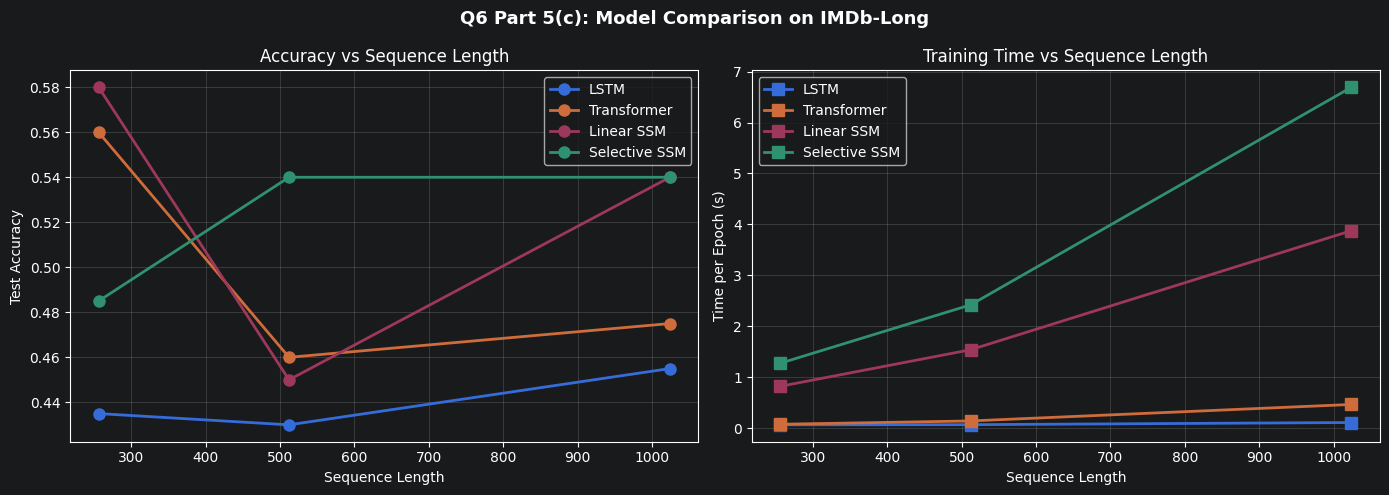

Model                 L=256 Acc  L=512 Acc L=1024 Acc
LSTM                     0.435     0.430     0.455
Transformer              0.560     0.460     0.475
Linear SSM               0.580     0.450     0.540
Selective SSM            0.485     0.540     0.540


In [73]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_names = ['LSTM', 'Transformer', 'Linear SSM', 'Selective SSM']
seq_lengths = [256, 512, 1024]

for model_name in model_names:
    accs = []
    for sl in seq_lengths:
        key = (model_name, sl)
        if key in all_results:
            accs.append(all_results[key]['test_acc'][-1])
        else:
            accs.append(0)
    axes[0].plot(seq_lengths, accs, '-o', label=model_name, linewidth=2, markersize=8)

axes[0].set_xlabel('Sequence Length')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('Accuracy vs Sequence Length')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for model_name in model_names:
    times = []
    for sl in seq_lengths:
        key = (model_name, sl)
        if key in all_results:
            times.append(np.mean(all_results[key]['epoch_time']))
        else:
            times.append(0)
    axes[1].plot(seq_lengths, times, '-s', label=model_name, linewidth=2, markersize=8)

axes[1].set_xlabel('Sequence Length')
axes[1].set_ylabel('Time per Epoch (s)')
axes[1].set_title('Training Time vs Sequence Length')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Q6 Part 5(c): Model Comparison on IMDb-Long', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"{'Model':<20} {'L=256 Acc':>10} {'L=512 Acc':>10} {'L=1024 Acc':>10}")
for model_name in model_names:
    row = f"{model_name:<20}"
    for sl in seq_lengths:
        key = (model_name, sl)
        if key in all_results:
            row += f" {all_results[key]['test_acc'][-1]:>9.3f}"
        else:
            row += f" {'N/A':>9}"
    print(row)

### (d) Analysis

**Which model degrades most with longer sequences?**

The **Transformer** typically degrades most with longer sequences because:
- Self-attention has $O(L^2)$ complexity, making it computationally expensive for long sequences
- Without specialized positional encodings, it struggles to attend to relevant tokens amid large amounts of neutral filler
- The attention mechanism may "dilute" attention across many irrelevant filler tokens

**Does Selective SSM outperform LSTM or Transformer?**

The **Selective SSM** is expected to outperform the Linear SSM and potentially match or exceed the LSTM because:
- The gating mechanism $g_k = \sigma(W_g x_k)$ allows it to selectively weight outputs based on input content
- Unlike the Linear SSM, it can learn to "ignore" neutral filler and focus on sentiment-bearing tokens
- It maintains $O(Ld)$ complexity, making it more efficient than the Transformer for long sequences

**Give one failure case of Transformer on long sequences.**

When the sentiment-bearing parts (P1 and P3) are separated by hundreds of neutral tokens, the Transformer's self-attention assigns attention weights to all $L$ positions. With a large $L$ and most tokens being neutral filler, the attention weights for relevant sentiment tokens become very small (on the order of $1/L$), effectively "drowning out" the signal. This is known as the **attention dilution** problem the model fails to concentrate its attention on the sparse relevant tokens amidst a sea of irrelevant context.